# Card Fraud Triage via Gaussian Mixture Density Scoring and Autoencoder Anomaly Detection

**Author:** Sarvesh Choudhary (Individual Project)  
**Dataset:** Credit Card Fraud Detection (Kaggle / ULB) — 284,807 transactions over 48 hours (~0.17% fraud base rate)  
**Deliverable:** Research & Engineering Prototype Notebook

> ⚠️ **DISCLAIMER:**  
> *This repository and notebook represent a **research/educational triage prototype**, not a production fraud detection system. In live financial environments, anomaly detection is typically one component of an ensemble/rules-based orchestration engine incorporating entity graphs, velocity engines, device telemetry, and human investigator feedback loops.*

---

## Executive Summary & Research Goal

In payment card fraud detection, legitimate transactions vastly outnumber frauds (~99.83% legitimate vs ~0.17% fraud). Supervised classifiers trained purely on historical fraud labels suffer from three severe real-world failure modes:
1. **Label Latency & Reporting Delays:** Chargebacks and fraud reports often arrive 30 to 90 days after transaction authorization.
2. **Concept Drift & Adversarial Adaptation:** Fraudsters actively mutate tactics, rendering historical supervised decision boundaries obsolete.
3. **Survivor/Reporting Bias:** Supervised models can only learn from frauds that were detected and tagged.

### The Anomaly Detection Framing
To overcome these limitations, we frame card fraud as an **unsupervised anomaly detection triage problem**:
- Models are trained **STRICTLY on legitimate transactions** ($Class = 0$).
- The models learn the compact structural manifold and probability density of standard cardholder behavior without ever observing fraud labels during training.
- We then systematically evaluate and compare:
  - **(A) AML Density Baseline:** Gaussian Mixture Model (GMM) negative log-likelihood density scoring: $-\log p(x)$
  - **(B) Deep Learning Manifold Model:** Undercomplete Autoencoder & Denoising Autoencoder reconstruction-error scoring: $\frac{1}{D}\|x - \hat{x}\|^2$
  - **(C) Reference Baselines:** Isolation Forest (unsupervised tree baseline) and Logistic Regression (supervised upper bound).
- All models are evaluated on the **exact same untouched, chronologically future, mixed test set** using ranking and budget-constrained triage metrics.


## 0. Environment Setup & Global Reproducibility

We set a global `SEED = 42` across all libraries (`numpy`, `torch`, `scikit-learn`, `random`) and enforce clean modular imports from `src/`.

In [1]:
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

# Set non-interactive backend for headless plot generation if needed
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import Image, display

# Ensure repo root is in python path
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.data import set_seed, prepare_data, load_raw_data, get_dataset_summary
from src.gmm_model import tune_gmm, fit_gmm, score_samples_gmm, load_gmm
from src.autoencoder import train_autoencoder, score_samples_ae, load_autoencoder
from src.metrics import (
    compute_pr_auc, compute_roc_auc, recall_at_fpr, precision_at_k,
    bootstrap_pr_auc_ci, select_thresholds_on_val, evaluate_threshold_on_test,
    compute_comprehensive_metrics
)

SEED = 42
set_seed(SEED)
sns.set_theme(style="whitegrid", font_scale=1.1)
%matplotlib inline

print(f"PyTorch version: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")


PyTorch version: 2.14.1 | CUDA available: False


## 1. Exploratory Data Analysis (EDA)

We examine dataset dimensions, data types, missing values, duplicates, class imbalance, transaction amount distributions, and transaction timestamps across the 48-hour recording window.

In [2]:
raw_df = load_raw_data(os.path.join(repo_root, "data/creditcard.csv"))
eda_summary = get_dataset_summary(raw_df)

print("="*60)
print("DATASET INTEGRITY & EXPLORATORY SUMMARY")
print("="*60)
print(f"Total Rows:            {eda_summary['total_rows']:,}")
print(f"Total Features:        {eda_summary['n_features']} (Time, V1..V28, Amount, Class)")
print(f"Missing Values:        {eda_summary['missing_values']}")
print(f"Duplicate Rows:        {eda_summary['duplicate_rows']:,} (retained as valid repeated txn timestamps/amounts)")
print(f"Legitimate Txns (0):   {eda_summary['legit_count']:,} ({100 - eda_summary['fraud_base_rate']*100:.3f}%)")
print(f"Fraudulent Txns (1):   {eda_summary['fraud_count']:,} ({eda_summary['fraud_base_rate']*100:.3f}%)")
print(f"Overall Base Rate:     {eda_summary['fraud_base_rate']:.6f} (~1 in {int(1/eda_summary['fraud_base_rate'])} txns)")
print(f"Total Time Duration:   {eda_summary['time_span_hours']:.2f} hours (~2 full calendar days)")
print("="*60)


DATASET INTEGRITY & EXPLORATORY SUMMARY
Total Rows:            284,807
Total Features:        31 (Time, V1..V28, Amount, Class)
Missing Values:        0
Duplicate Rows:        1,081 (retained as valid repeated txn timestamps/amounts)
Legitimate Txns (0):   284,315 (99.827%)
Fraudulent Txns (1):   492 (0.173%)
Overall Base Rate:     0.001727 (~1 in 578 txns)
Total Time Duration:   48.00 hours (~2 full calendar days)


### Why Accuracy is a Misleading Metric in Fraud Detection

In highly imbalanced datasets (~0.17% fraud prevalence), **Accuracy is fundamentally deceptive**:
- A naive dummy baseline that predicts every single transaction is legitimate ($Class = 0$) achieves **99.827% accuracy**.
- However, this classifier catches **0 out of 492 frauds** ($Recall = 0\%$, $PR	ext{-}AUC = 0.0017$).
- In fraud operations, the objective is asymmetric: undetected fraud yields direct chargeback and reputational losses, while false alerts consume analyst triage bandwidth.
- Therefore, our primary metric is **Precision-Recall AUC (Average Precision)**, complemented by **Recall at strict operational False Positive Rate budgets (0.1%, 0.5%, 1.0%)** and **Precision@K (review capacity)**.


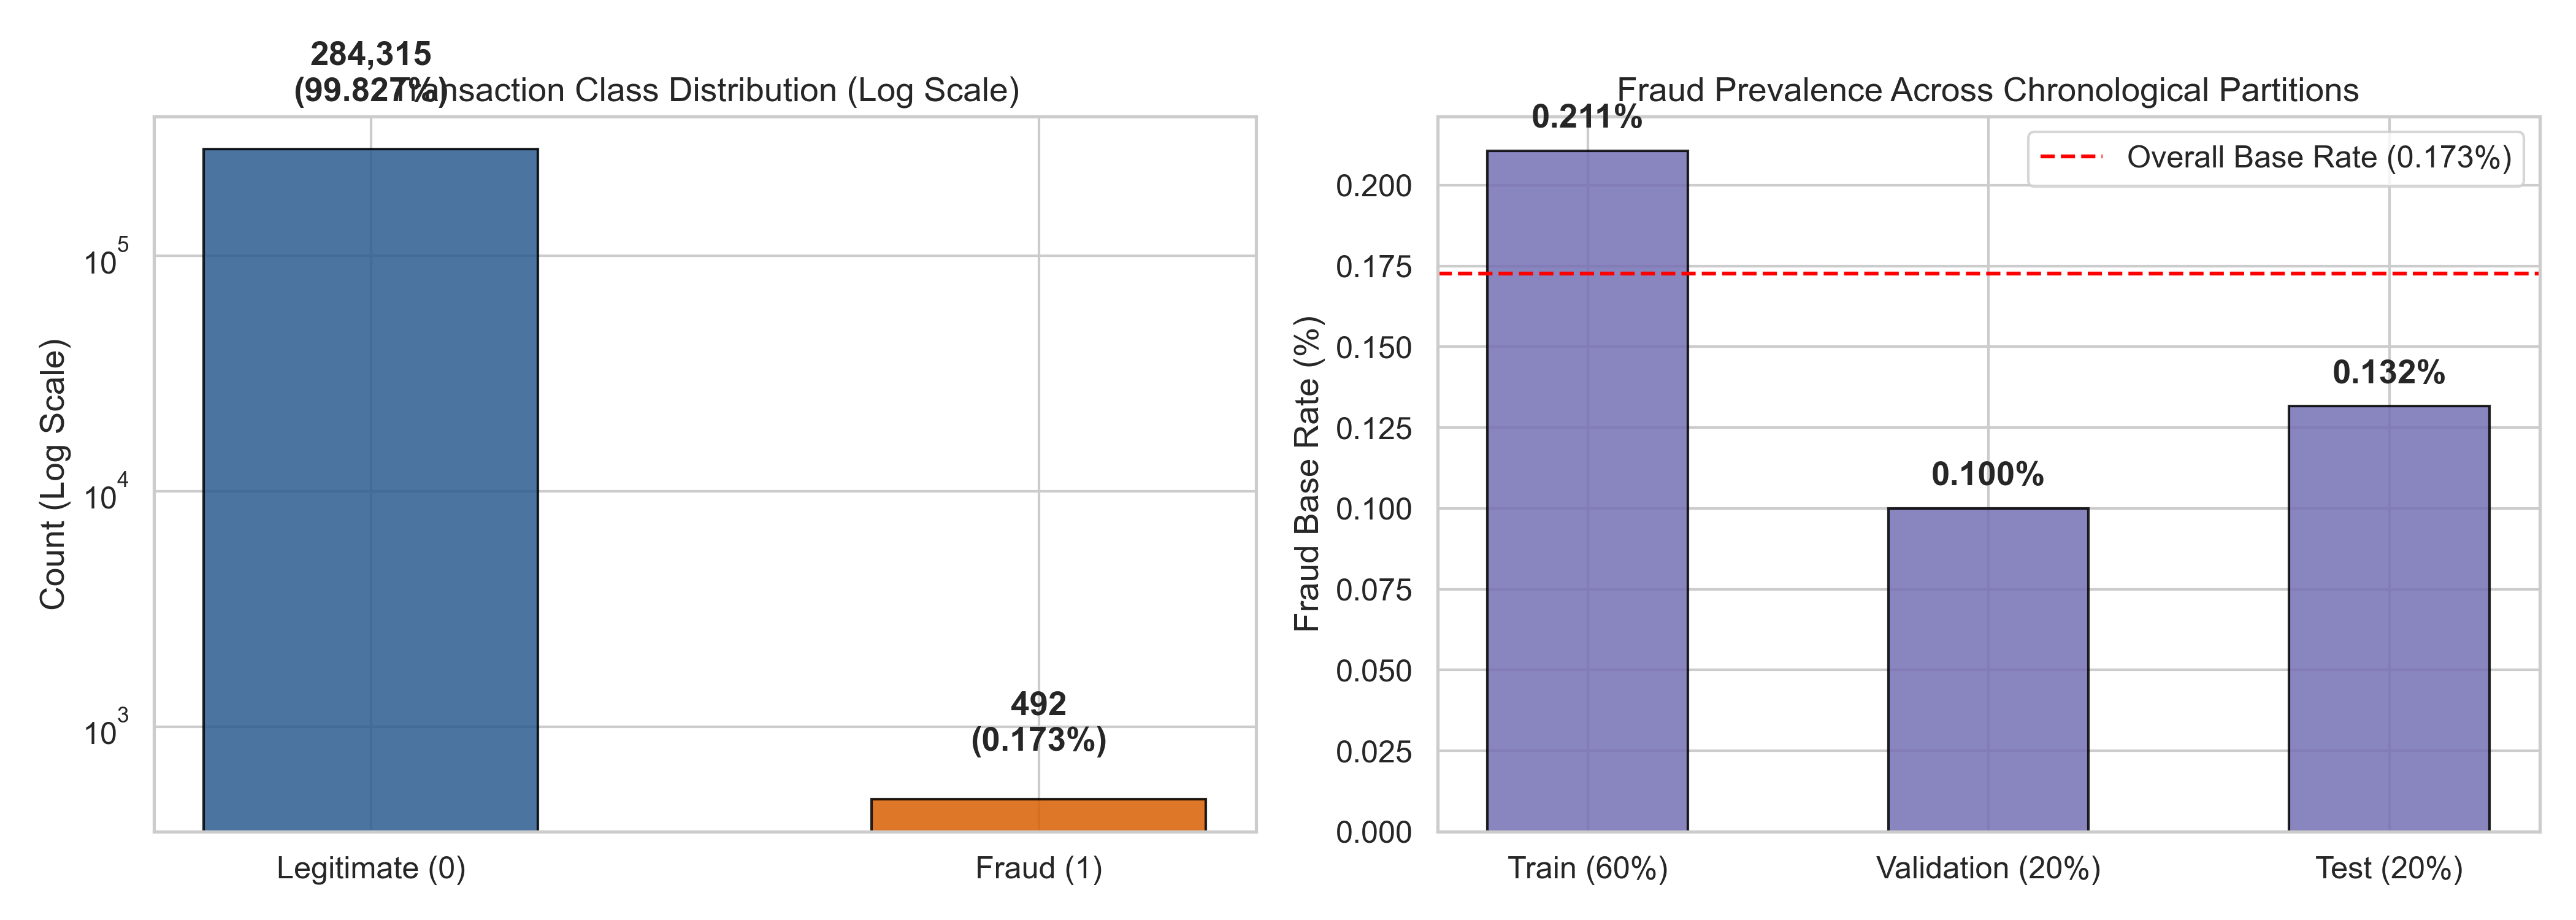

In [3]:
# Visual 1: Class Imbalance Distribution
display(Image(filename=os.path.join(repo_root, "results/eda_class_imbalance.png")))


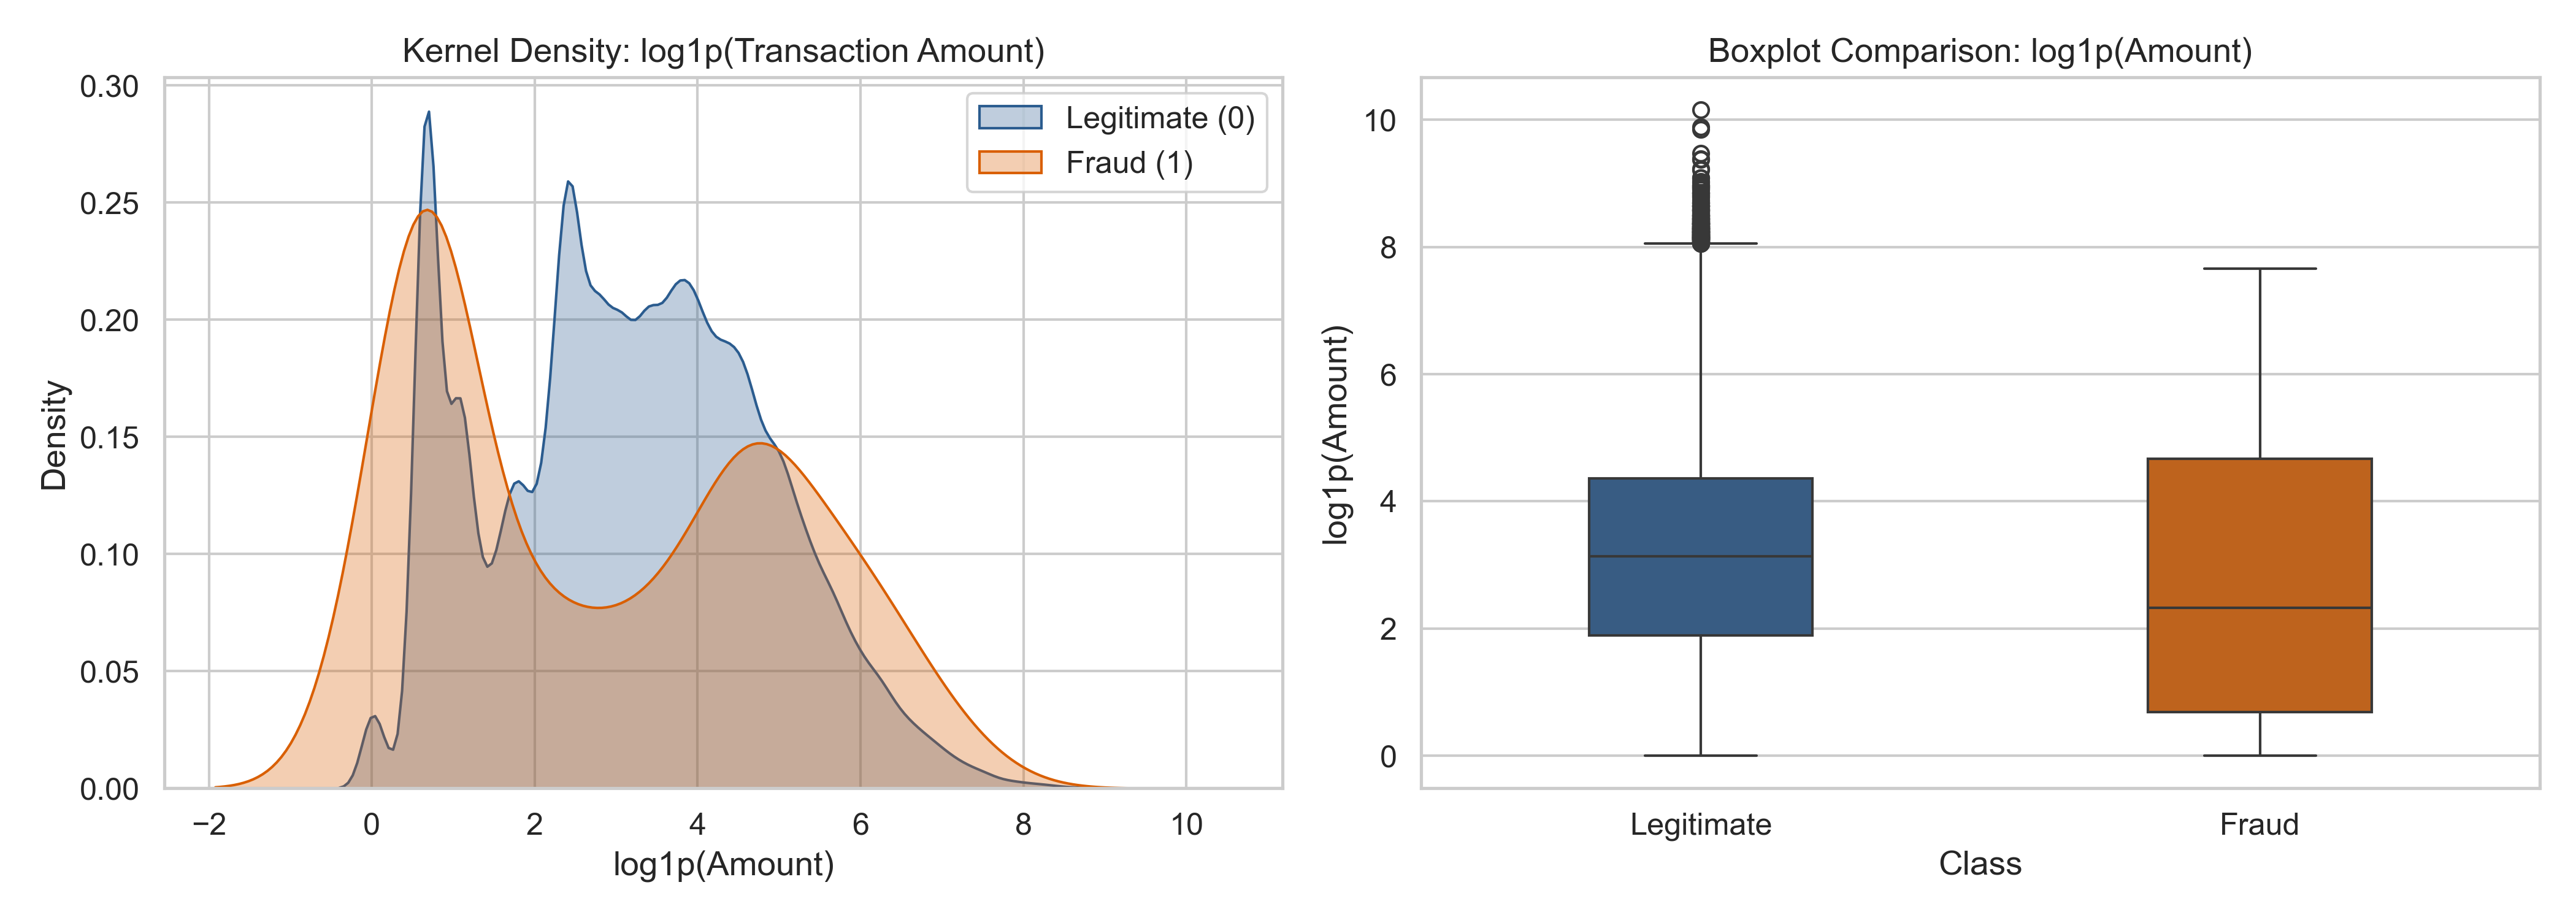

Transaction Amount Statistics:
  Legitimate - Mean: $88.29 | Median: $22.00 | Max: $25691.16
  Fraudulent - Mean: $122.21 | Median: $9.25 | Max: $2125.87


In [4]:
# Visual 2: Amount Distribution (log1p transformed)
display(Image(filename=os.path.join(repo_root, "results/eda_amount_distribution.png")))

print("Transaction Amount Statistics:")
print(f"  Legitimate - Mean: ${eda_summary['amount_stats']['legit_mean']:.2f} | Median: ${eda_summary['amount_stats']['legit_median']:.2f} | Max: ${eda_summary['amount_stats']['legit_max']:.2f}")
print(f"  Fraudulent - Mean: ${eda_summary['amount_stats']['fraud_mean']:.2f} | Median: ${eda_summary['amount_stats']['fraud_median']:.2f} | Max: ${eda_summary['amount_stats']['fraud_max']:.2f}")


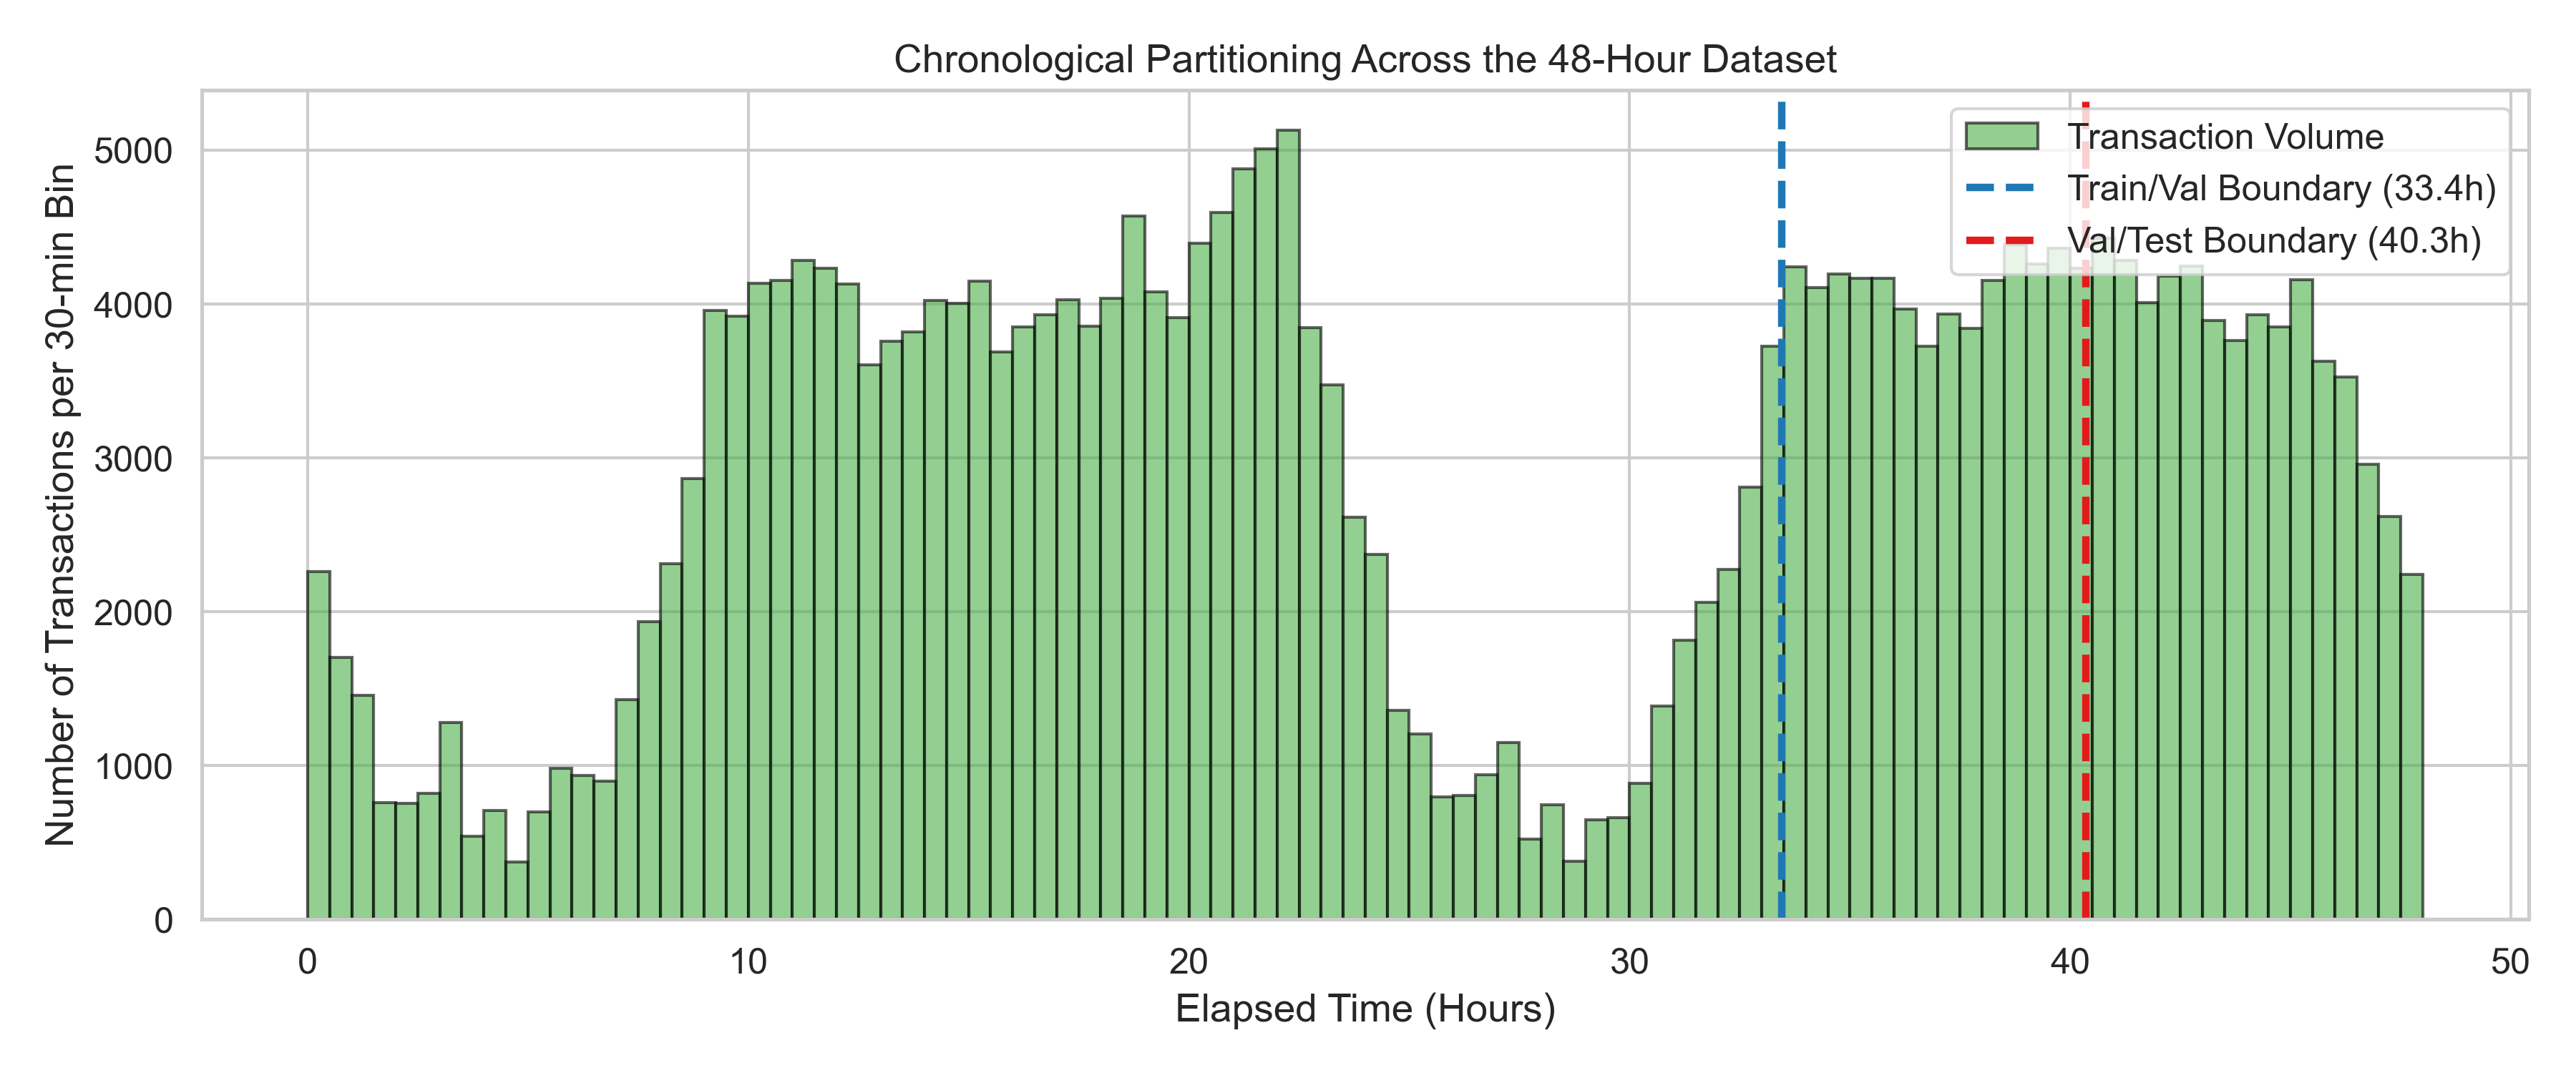

In [5]:
# Visual 3: Chronological Transaction Timeline over 48 Hours
display(Image(filename=os.path.join(repo_root, "results/eda_time_distribution.png")))


## 2. Preprocessing & Leakage-Free Chronological Splitting

### Critical Anti-Leakage Protocol:
1. **Chronological Partitioning:** Financial transactions exhibit temporal ordering and potential behavioral shifts. Shuffling transactions randomly causes severe data leakage (past predicting past using future data). We sort strictly by `Time`:
   - **Train:** First 60% of timeline (0.00h to 33.44h)
   - **Validation:** Next 20% of timeline (33.44h to 40.35h)
   - **Test:** Final 20% of timeline (40.35h to 48.00h)
2. **Unsupervised Training Restriction:** Models are fit **ONLY on legitimate transactions** in the training partition (`Class == 0`). Fraud labels are never observed during model fitting.
3. **Scaler Fitting Boundary:** `StandardScaler` is fitted **strictly on legitimate training transactions only**, and then applied via `.transform()` to validation and test partitions.
4. **Validation vs Test Role:** The mixed validation set is used solely for model selection, early stopping, and threshold tuning. The test set remains completely untouched until final evaluation.


In [6]:
data_dict = prepare_data(os.path.join(repo_root, "data/creditcard.csv"), seed=SEED)
stats = data_dict["stats"]

split_table = pd.DataFrame([
    {
        "Split Partition": stats["train"]["name"],
        "Total Txns": f"{stats['train']['total']:,}",
        "Legit (Class 0)": f"{stats['train']['legit']:,}",
        "Fraud (Class 1)": f"{stats['train']['fraud']:,}",
        "Base Rate (%)": f"{stats['train']['fraud_base_rate']*100:.3f}%",
        "Time Span (Hours)": f"{stats['train']['time_range_hours'][0]:.1f}h - {stats['train']['time_range_hours'][1]:.1f}h",
        "Role in Pipeline": "Fit Scaler & Unsupervised Anomaly Models (Legit only)"
    },
    {
        "Split Partition": stats["val"]["name"],
        "Total Txns": f"{stats['val']['total']:,}",
        "Legit (Class 0)": f"{stats['val']['legit']:,}",
        "Fraud (Class 1)": f"{stats['val']['fraud']:,}",
        "Base Rate (%)": f"{stats['val']['fraud_base_rate']*100:.3f}%",
        "Time Span (Hours)": f"{stats['val']['time_range_hours'][0]:.1f}h - {stats['val']['time_range_hours'][1]:.1f}h",
        "Role in Pipeline": "Early Stopping & Operating Threshold Selection"
    },
    {
        "Split Partition": stats["test"]["name"],
        "Total Txns": f"{stats['test']['total']:,}",
        "Legit (Class 0)": f"{stats['test']['legit']:,}",
        "Fraud (Class 1)": f"{stats['test']['fraud']:,}",
        "Base Rate (%)": f"{stats['test']['fraud_base_rate']*100:.3f}%",
        "Time Span (Hours)": f"{stats['test']['time_range_hours'][0]:.1f}h - {stats['test']['time_range_hours'][1]:.1f}h",
        "Role in Pipeline": "Untouched Out-of-Time Final Evaluation"
    }
])

display(split_table)


Split Partition,Total Txns,Legit (Class 0),Fraud (Class 1),Base Rate (%),Time Span (Hours),Role in Pipeline
Train (first 60%),"170,884","170,524",360,0.211%,0.0h - 33.4h,Fit Scaler & Unsupervised Anomaly Models (Legit only)
Validation (middle 20%),"56,961","56,904",57,0.100%,33.4h - 40.3h,Early Stopping & Operating Threshold Selection
Test (final 20%),"56,962","56,887",75,0.132%,40.3h - 48.0h,Untouched Out-of-Time Final Evaluation


## 3. AML Baseline: Gaussian Mixture Model (GMM)

### Density Scoring Methodology:
The Anti-Money Laundering (AML) density baseline assumes legitimate transactions are generated by a mixture of $K$ multivariate Gaussian components:
$$p(x) = \sum_{k=1}^K \pi_k \mathcal{N}(x \mid \mu_k, \Sigma_k)$$

- **Anomaly Score:** Defined as the negative log-likelihood under the fitted density:
$$Score(x) = -\log p(x)$$
Transactions situated in sparse, low-density regions receive large positive anomaly scores.
- **Model Selection via AIC / BIC:** We evaluate $K \in \{1, \dots, 8\}$ with both diagonal and full covariance matrices on a deterministic subsample of 25,000 legitimate training rows.
- **Numerical Stability Safeguard:** In 29 dimensions, sample covariance matrices can become ill-conditioned or non-positive definite. We inject `reg_covar = 1e-4` along the diagonal to ensure numerical stability.


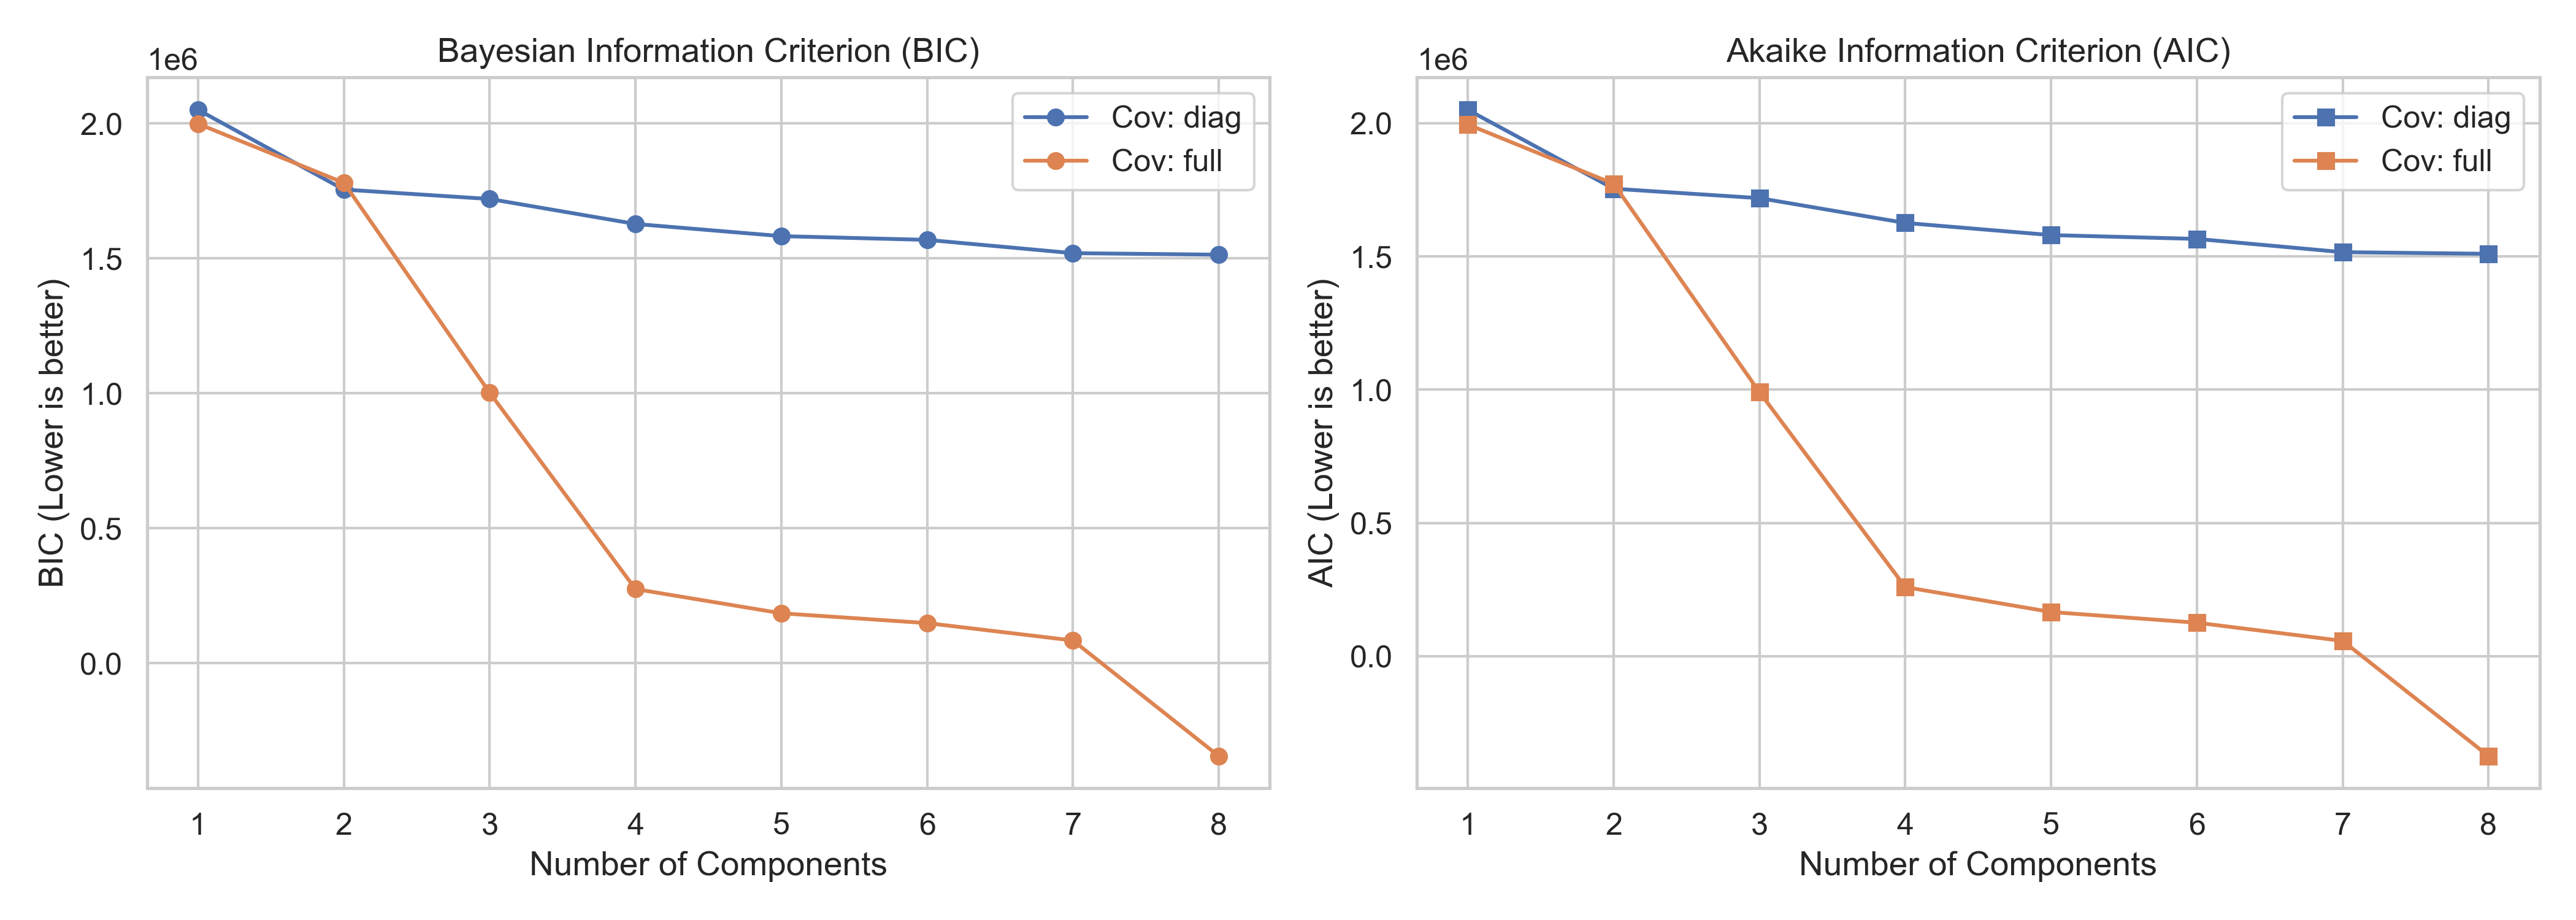

Loaded Saved GMM Model:
  Components (K):  8
  Covariance Type: full
  reg_covar:       0.0001
  Converged:       True


In [7]:
# Display GMM AIC/BIC Selection Curves
display(Image(filename=os.path.join(repo_root, "results/gmm_aic_bic_curve.png")))

# Load fitted GMM model and verify score samples
gmm = load_gmm(os.path.join(repo_root, "models/gmm_model.joblib"))
print("Loaded Saved GMM Model:")
print(f"  Components (K):  {gmm.n_components}")
print(f"  Covariance Type: {gmm.covariance_type}")
print(f"  reg_covar:       {gmm.reg_covar}")
print(f"  Converged:       {gmm.converged_}")


## 4. Deep Learning Anomaly Detection: PyTorch Autoencoders

### Architecture & Manifold Learning:
Autoencoders compress normal behavior into a low-dimensional bottleneck ($d=5$) and reconstruct the original 29-dimensional input:
- **Encoder:** $29 \to 20 \to 10 \to 5$ (ReLU activations, Batch Normalization)
- **Decoder:** $5 \to 10 \to 20 \to 29$ (ReLU activations, Batch Normalization)
- **Anomaly Score:** Mean Squared Reconstruction Error per transaction:
$$Score(x) = \frac{1}{D} \sum_{j=1}^D (x_j - \hat{x}_j)^2$$

### Denoising Autoencoder Variant:
To prevent the autoencoder from learning an identity mapping and encourage robust manifold representations, the **Denoising Autoencoder (DAE)** injects zero-mean Gaussian noise ($\sigma = 0.15$) into inputs during training, but optimizes reconstruction loss against the *clean, uncorrupted* inputs.
Both models employ **Early Stopping** monitoring reconstruction error on legitimate validation rows only.


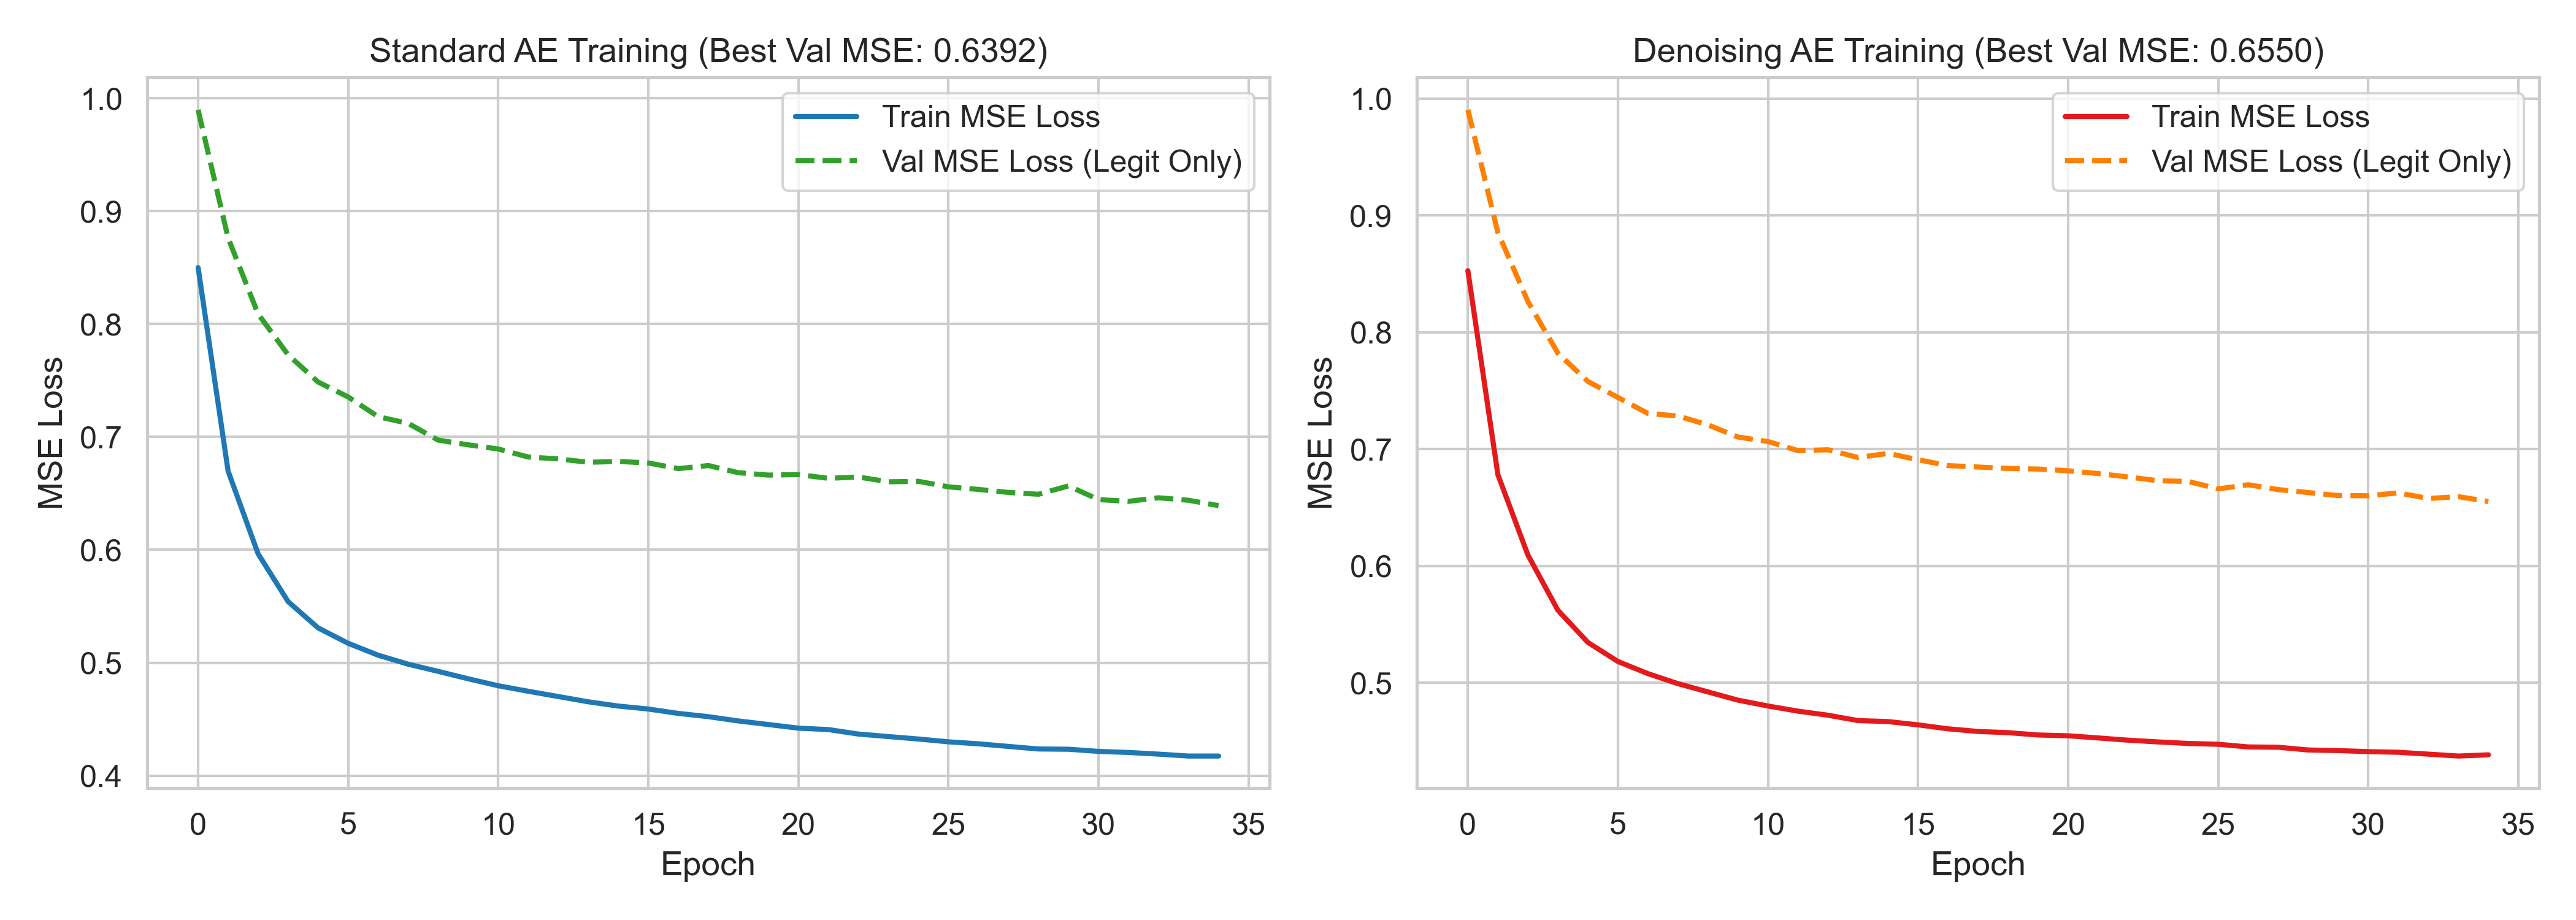

Successfully loaded Standard Autoencoder and Denoising Autoencoder models.


In [8]:
# Display Autoencoder Training & Validation Loss Curves
display(Image(filename=os.path.join(repo_root, "results/autoencoder_loss_curves.png")))

ae_model = load_autoencoder(os.path.join(repo_root, "models/autoencoder.pt"), device="cpu")
dae_model = load_autoencoder(os.path.join(repo_root, "models/denoising_autoencoder.pt"), device="cpu")
print("Successfully loaded Standard Autoencoder and Denoising Autoencoder models.")


## 5. Reference Baselines

To provide rigorous context, we include two reference benchmarks:
1. **Isolation Forest (Unsupervised Baseline):** An ensemble of random partition trees fit strictly on legitimate training data; anomaly score = `-score_samples(x)`.
2. **Logistic Regression (Supervised Upper Bound):** Trained with full access to fraud labels ($Class = 1$) on the training set with balanced class weights. This serves as an empirical upper bound illustrating the theoretical gap between unsupervised novelty detection and supervised discriminative learning.


In [9]:
# Load final comparison table
comparison_df = pd.read_csv(os.path.join(repo_root, "results/comparison_table.csv"))
display(comparison_df)


Model,PR-AUC (Primary),ROC-AUC,Recall @ 0.1% FPR,Recall @ 0.5% FPR,Recall @ 1.0% FPR,Precision @ 100,Precision @ 500,Precision @ 1000,Test Base Rate
GMM (AML Baseline),"0.2196 [0.1480, 0.3174]",0.9458,30.67%,65.33%,68.00%,26.00%,10.20%,5.30%,0.132%
Autoencoder,"0.2185 [0.1681, 0.2896]",0.9660,41.33%,77.33%,81.33%,33.00%,11.80%,6.30%,0.132%
Denoising Autoencoder,"0.1600 [0.1189, 0.2166]",0.9462,33.33%,70.67%,74.67%,28.00%,11.20%,5.90%,0.132%
Hybrid (GMM + Autoencoder),"0.2429 [0.1864, 0.3240]",0.9587,48.00%,76.00%,78.67%,38.00%,11.80%,6.10%,0.132%
Isolation Forest (Extra Baseline),"0.0950 [0.0723, 0.1279]",0.9525,1.33%,54.67%,69.33%,9.00%,9.80%,5.80%,0.132%
Logistic Regression (Supervised Upper Bound),"0.7473 [0.6331, 0.8533]",0.9818,80.00%,85.33%,86.67%,60.00%,13.00%,6.60%,0.132%


## 6. Comprehensive Comparative Evaluation on Untouched Test Set

We now evaluate all models on the exact same chronologically held-out test set ($N = 56,962$ transactions, $75$ true frauds, Base Rate = $0.132\%$).
- **Primary Metric:** Precision-Recall AUC (Average Precision) with 95% Bootstrap Confidence Intervals (1,000 resamples).
- **Secondary Metric:** ROC-AUC.
- **Budget Metrics:** Recall at fixed False Positive Rate budgets (FPR = 0.1%, 0.5%, 1.0%).
- **Capacity Metrics:** Precision@K for $K \in \{100, 500, 1000\}$.


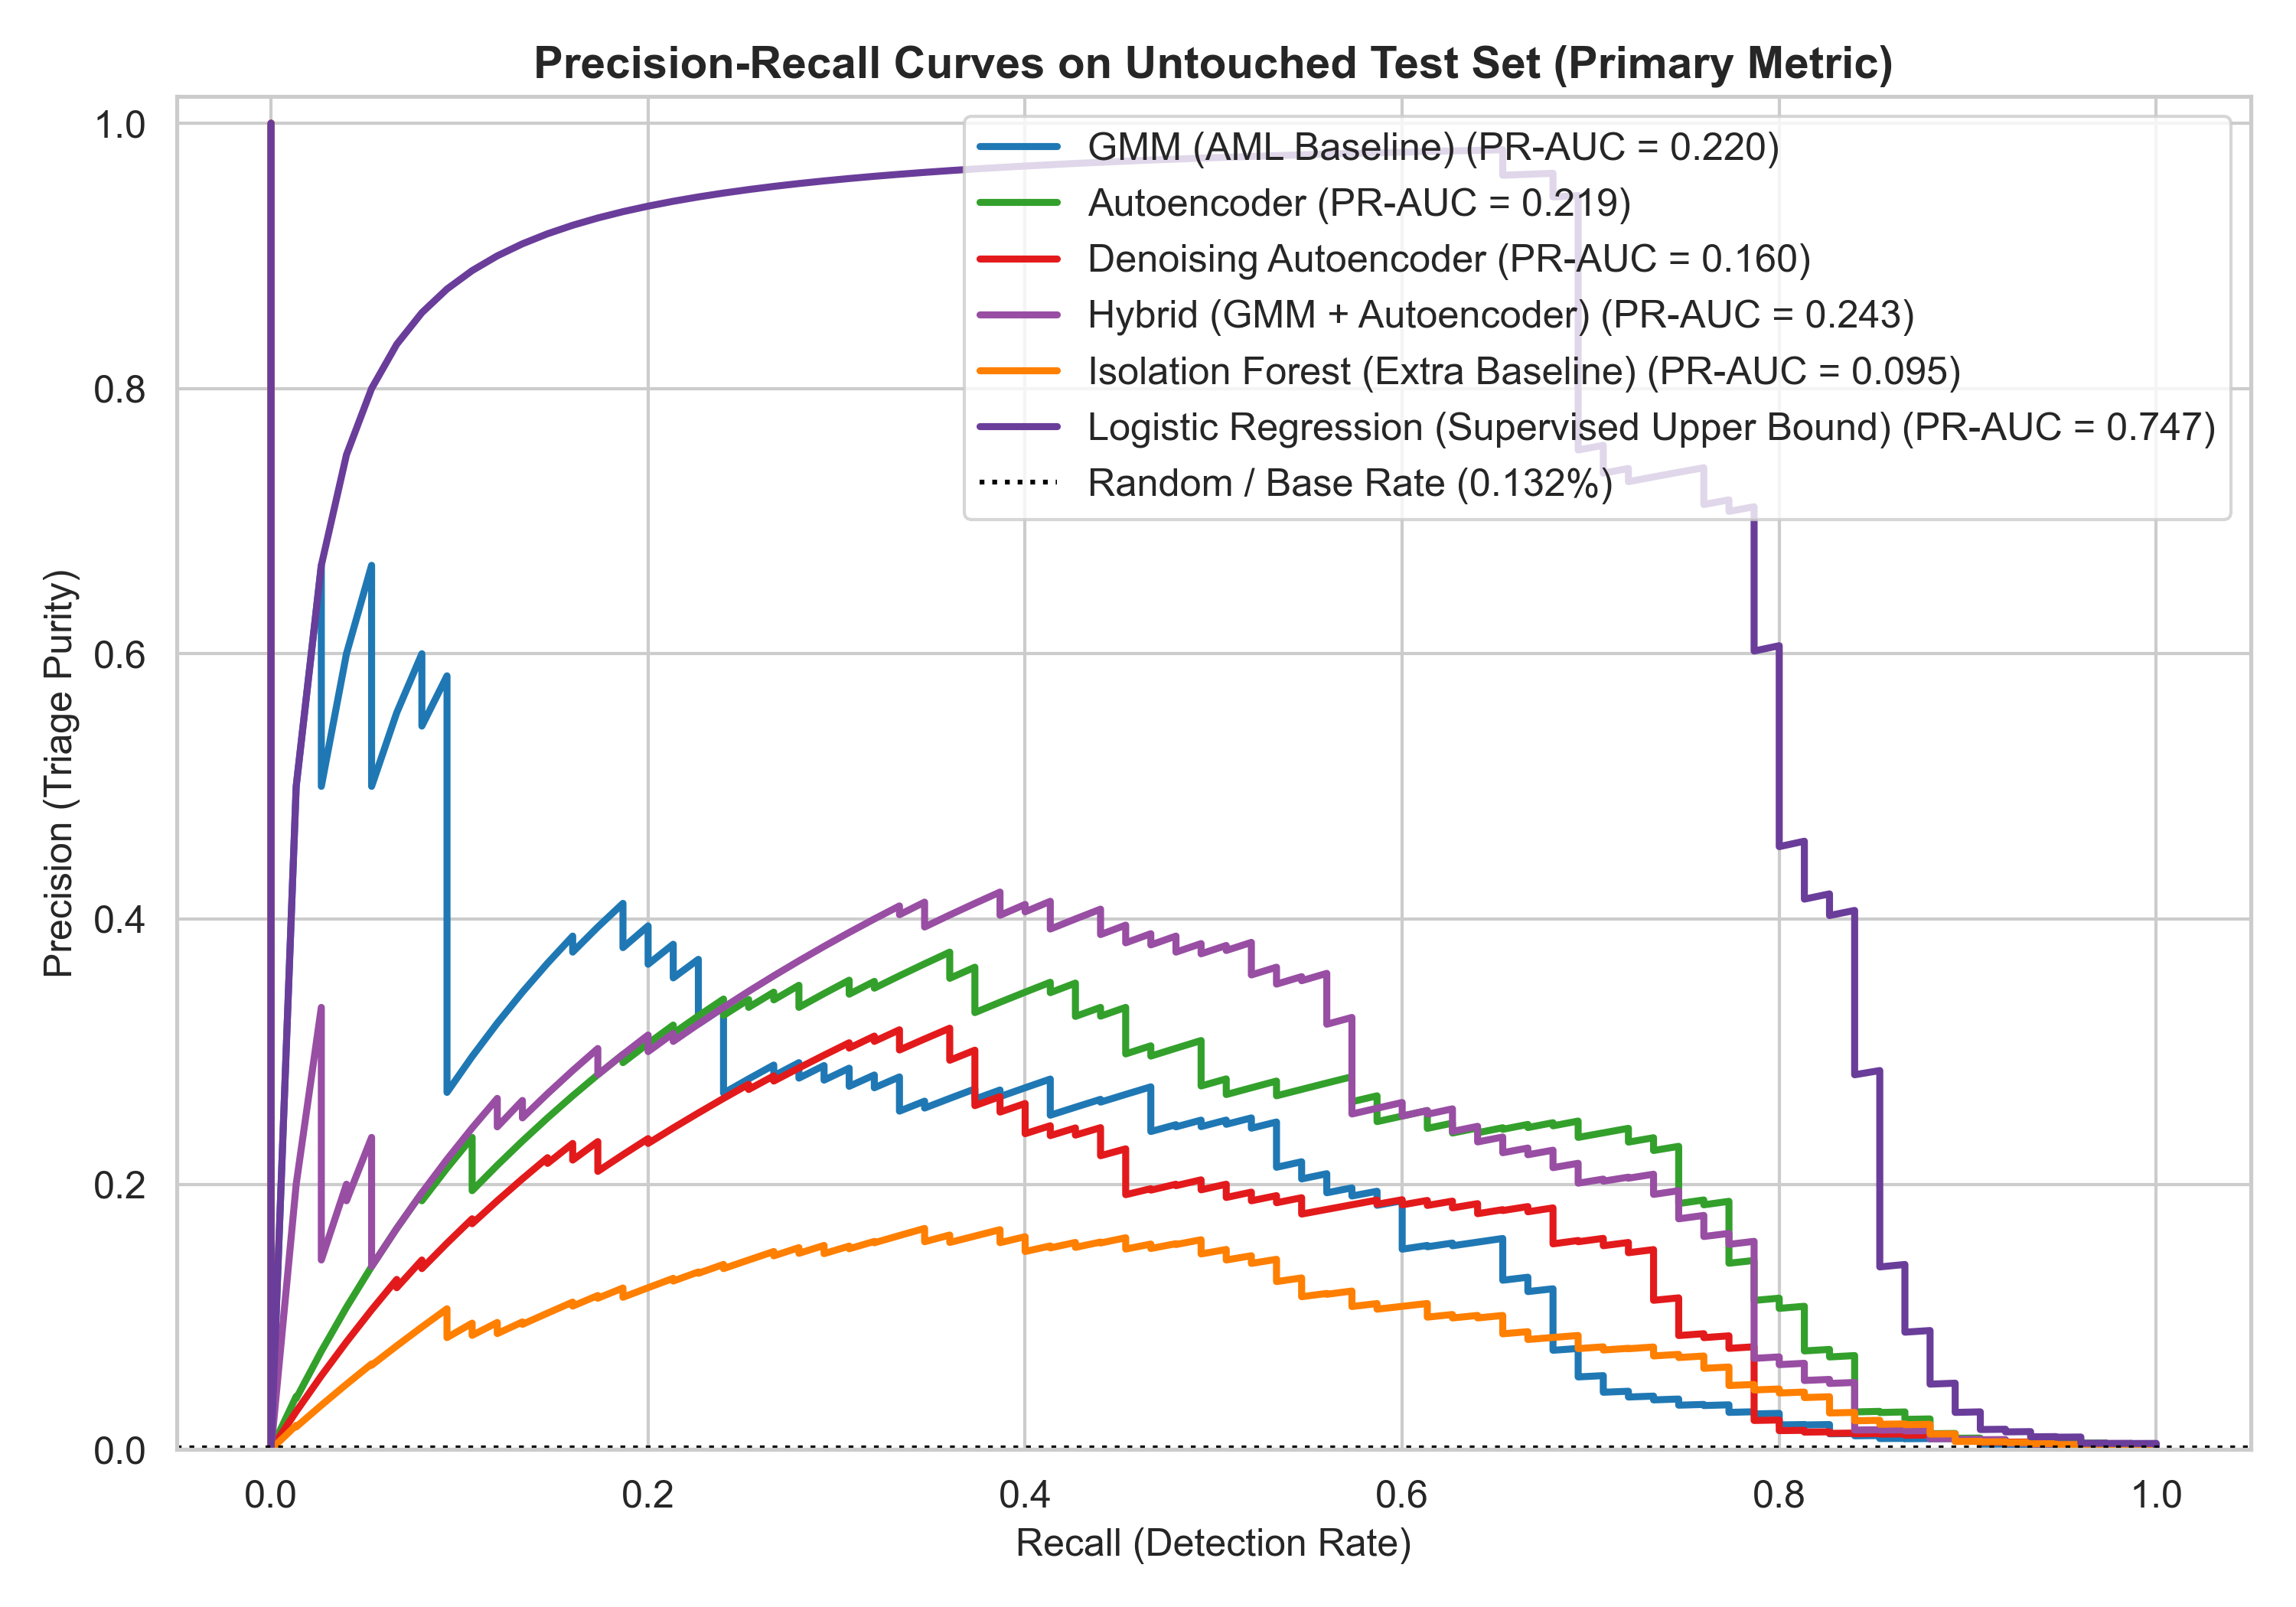

In [10]:
# Visual 4: Precision-Recall Curves (Primary Metric)
display(Image(filename=os.path.join(repo_root, "results/pr_curves_comparison.png")))


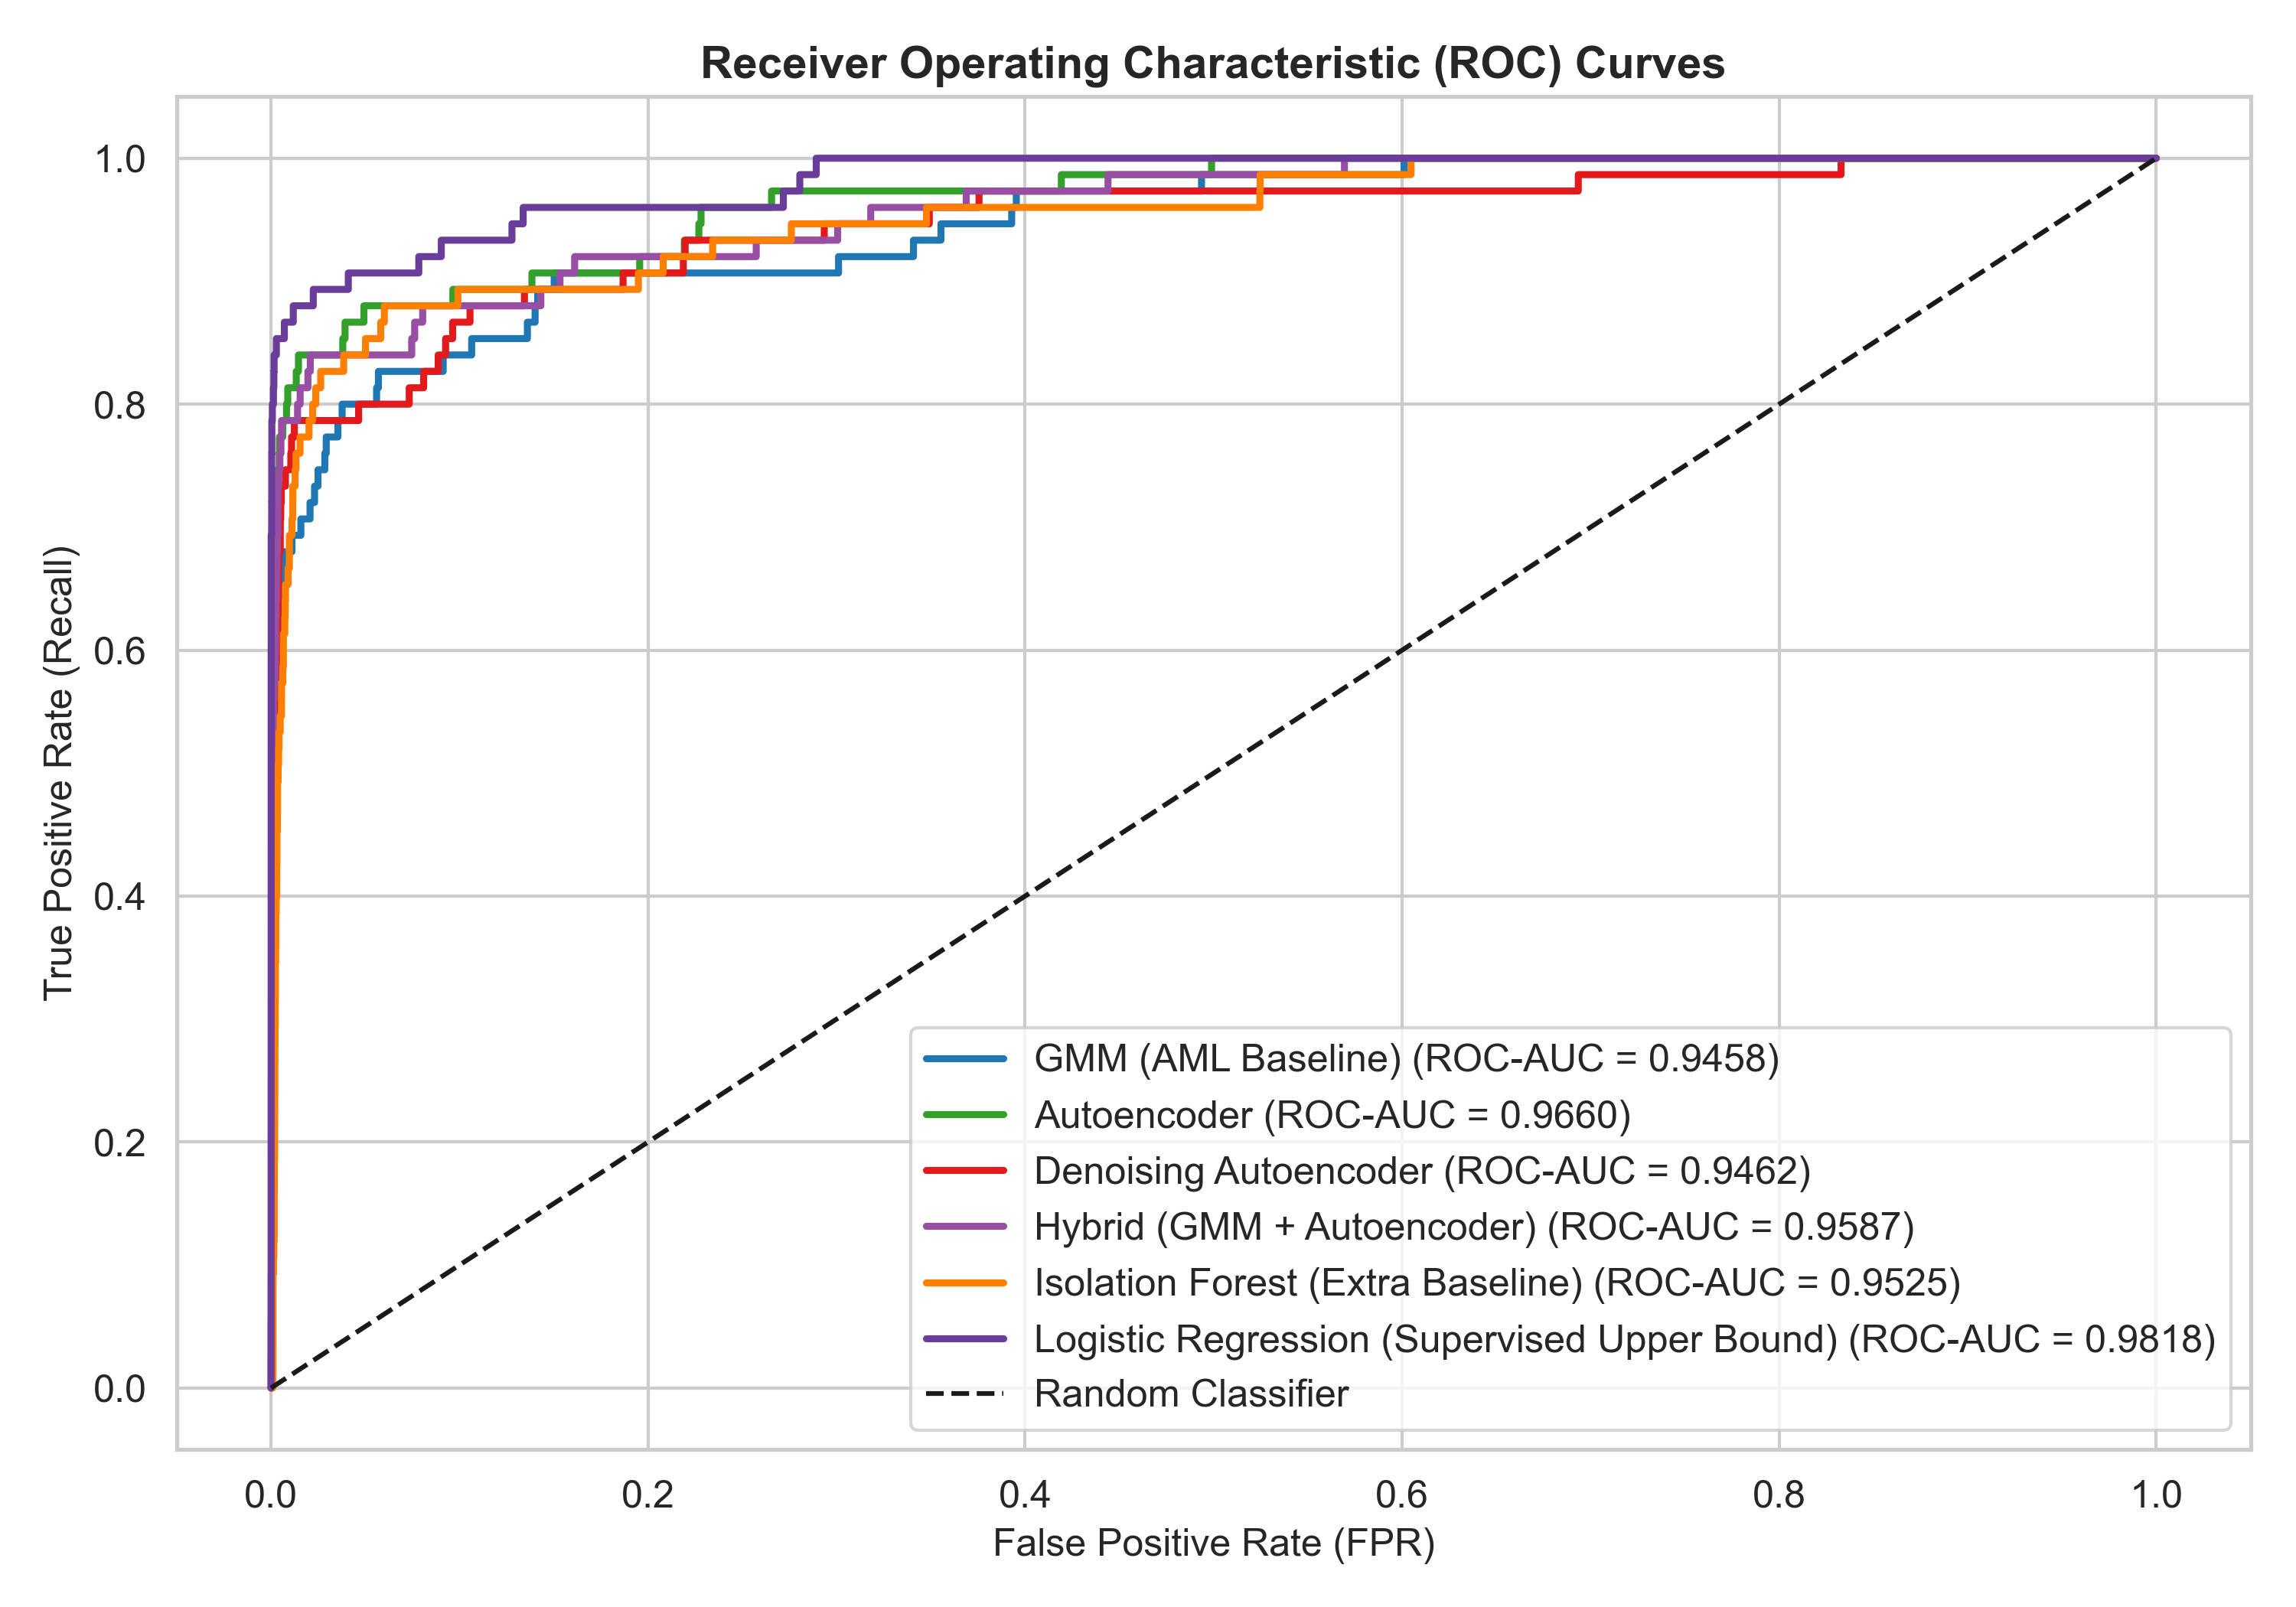

In [11]:
# Visual 5: ROC Curves
display(Image(filename=os.path.join(repo_root, "results/roc_curves_comparison.png")))


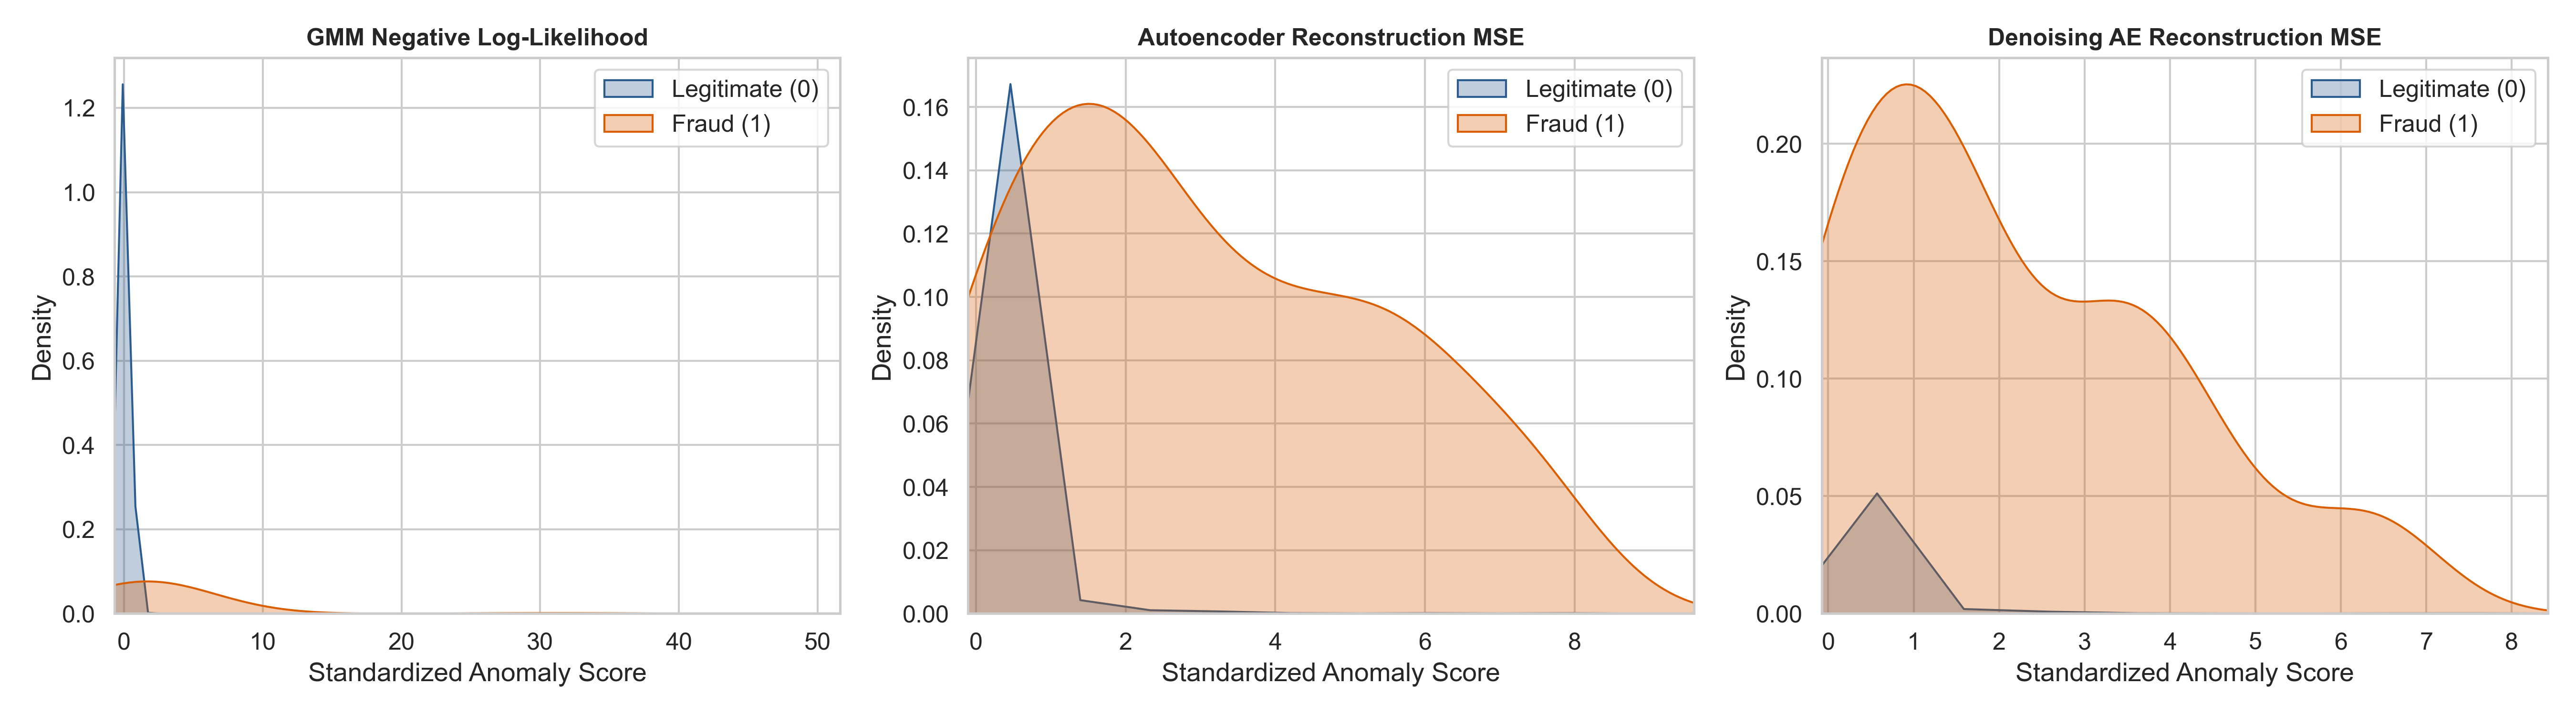

In [12]:
# Visual 6: Anomaly Score Separation Distributions
display(Image(filename=os.path.join(repo_root, "results/score_distributions.png")))


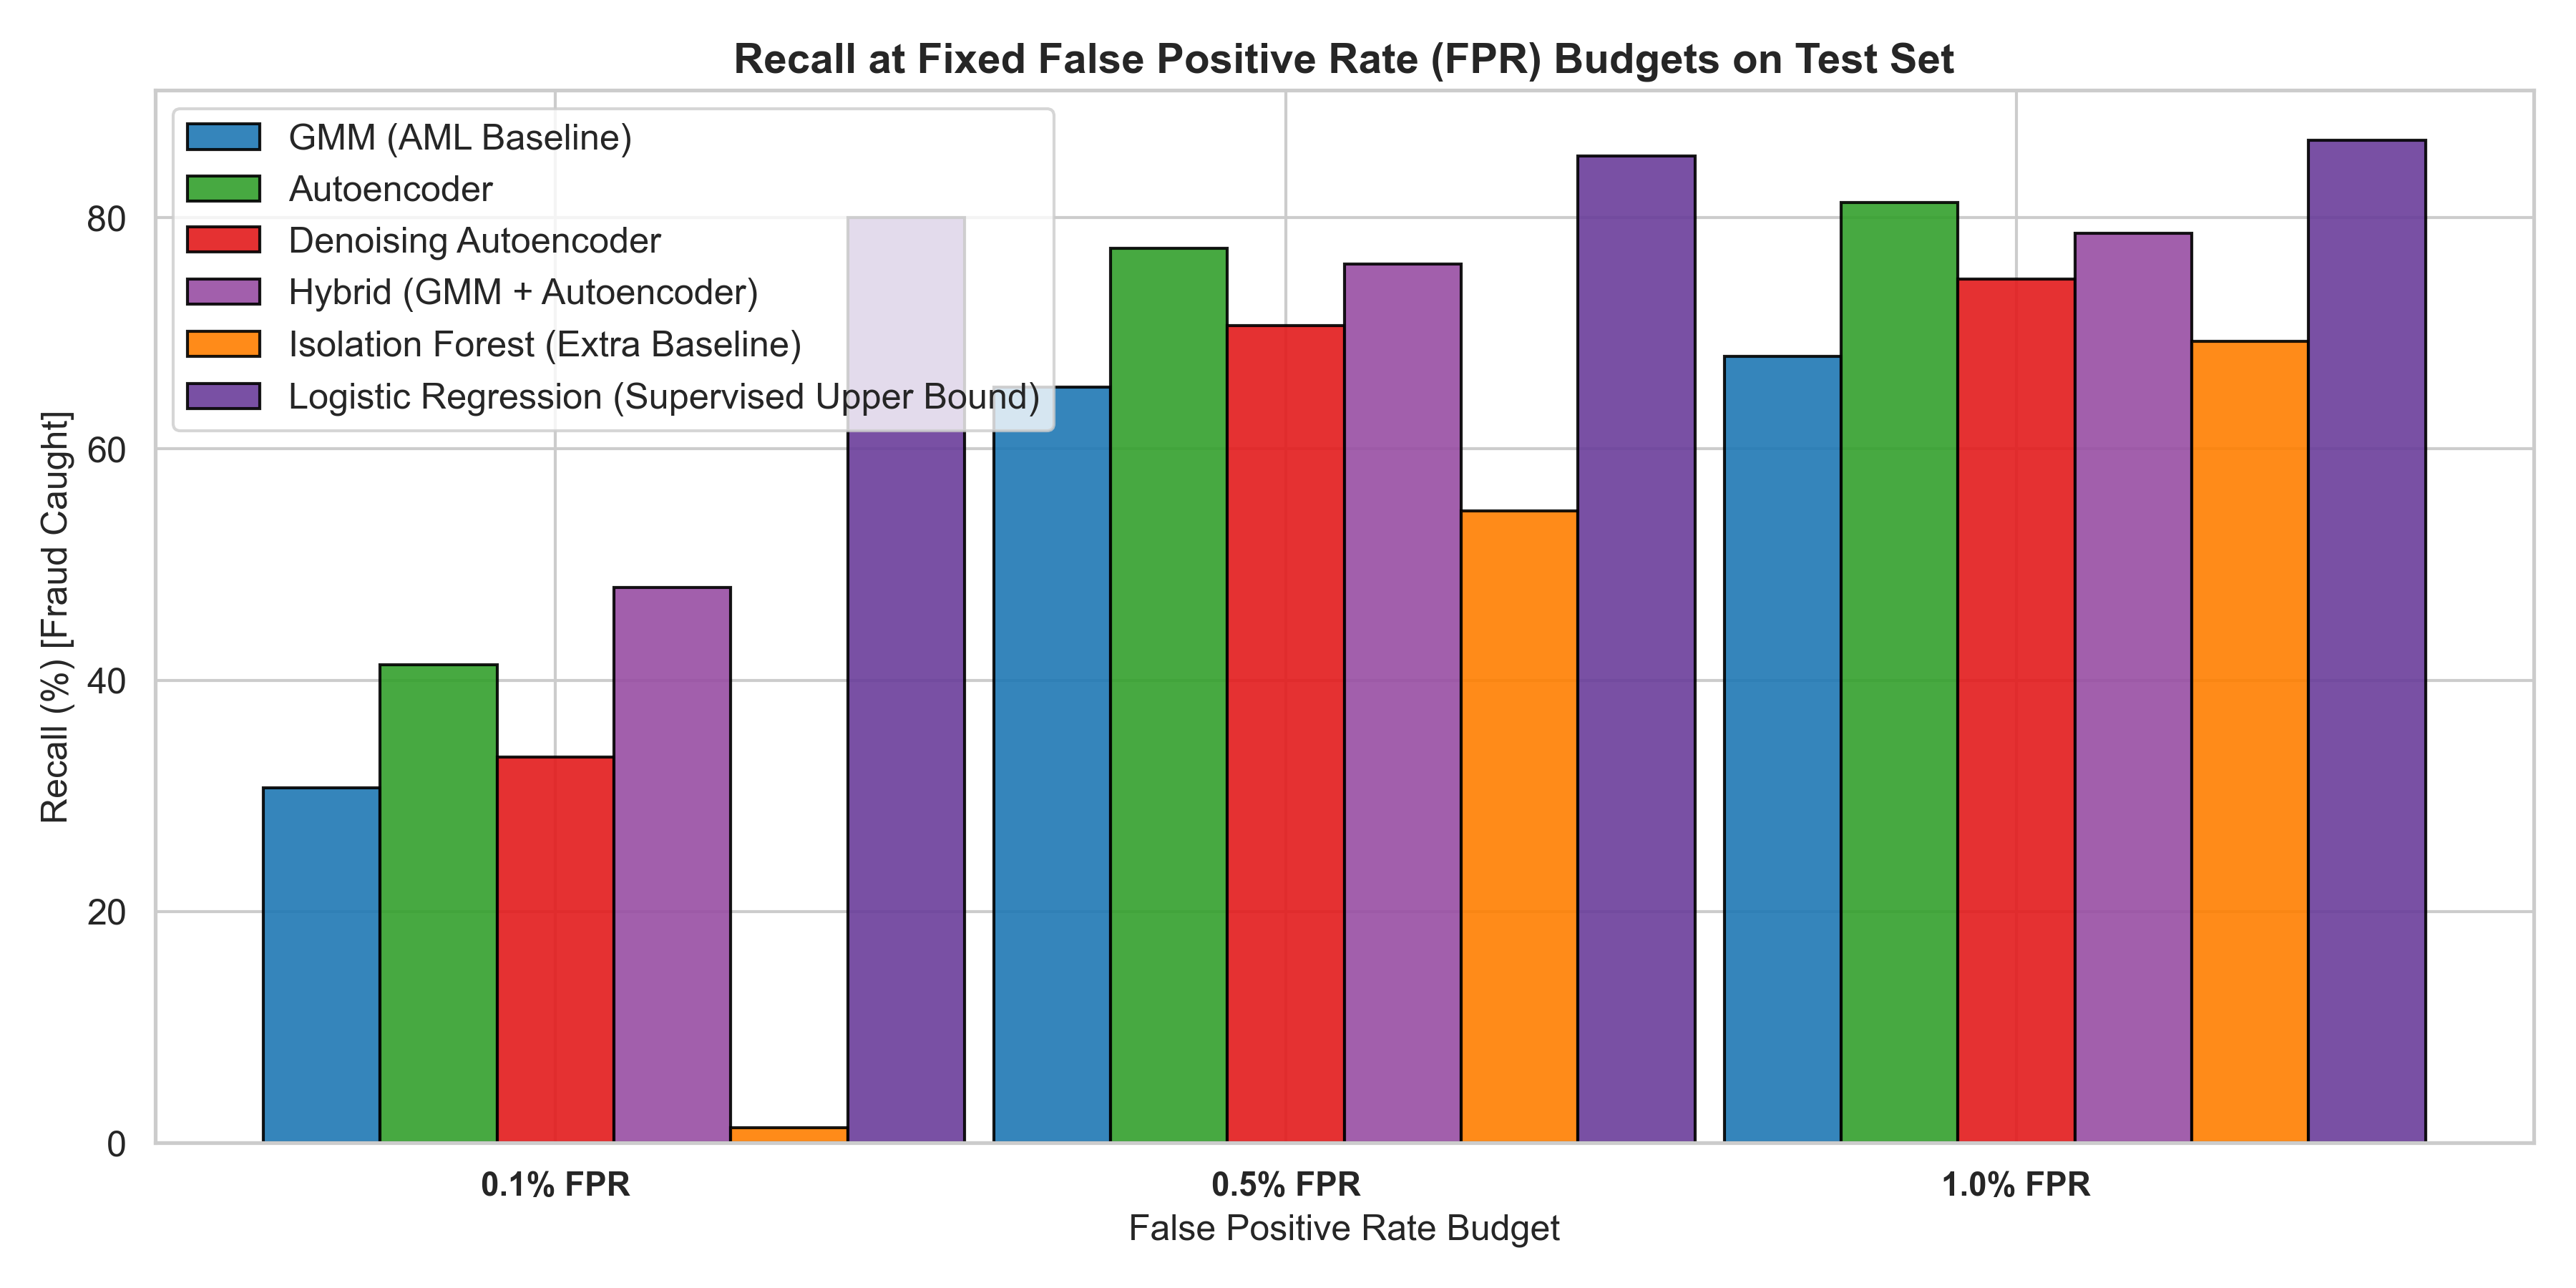

In [13]:
# Visual 7: Recall at Fixed False Positive Rate Budgets
display(Image(filename=os.path.join(repo_root, "results/recall_at_fpr_comparison.png")))


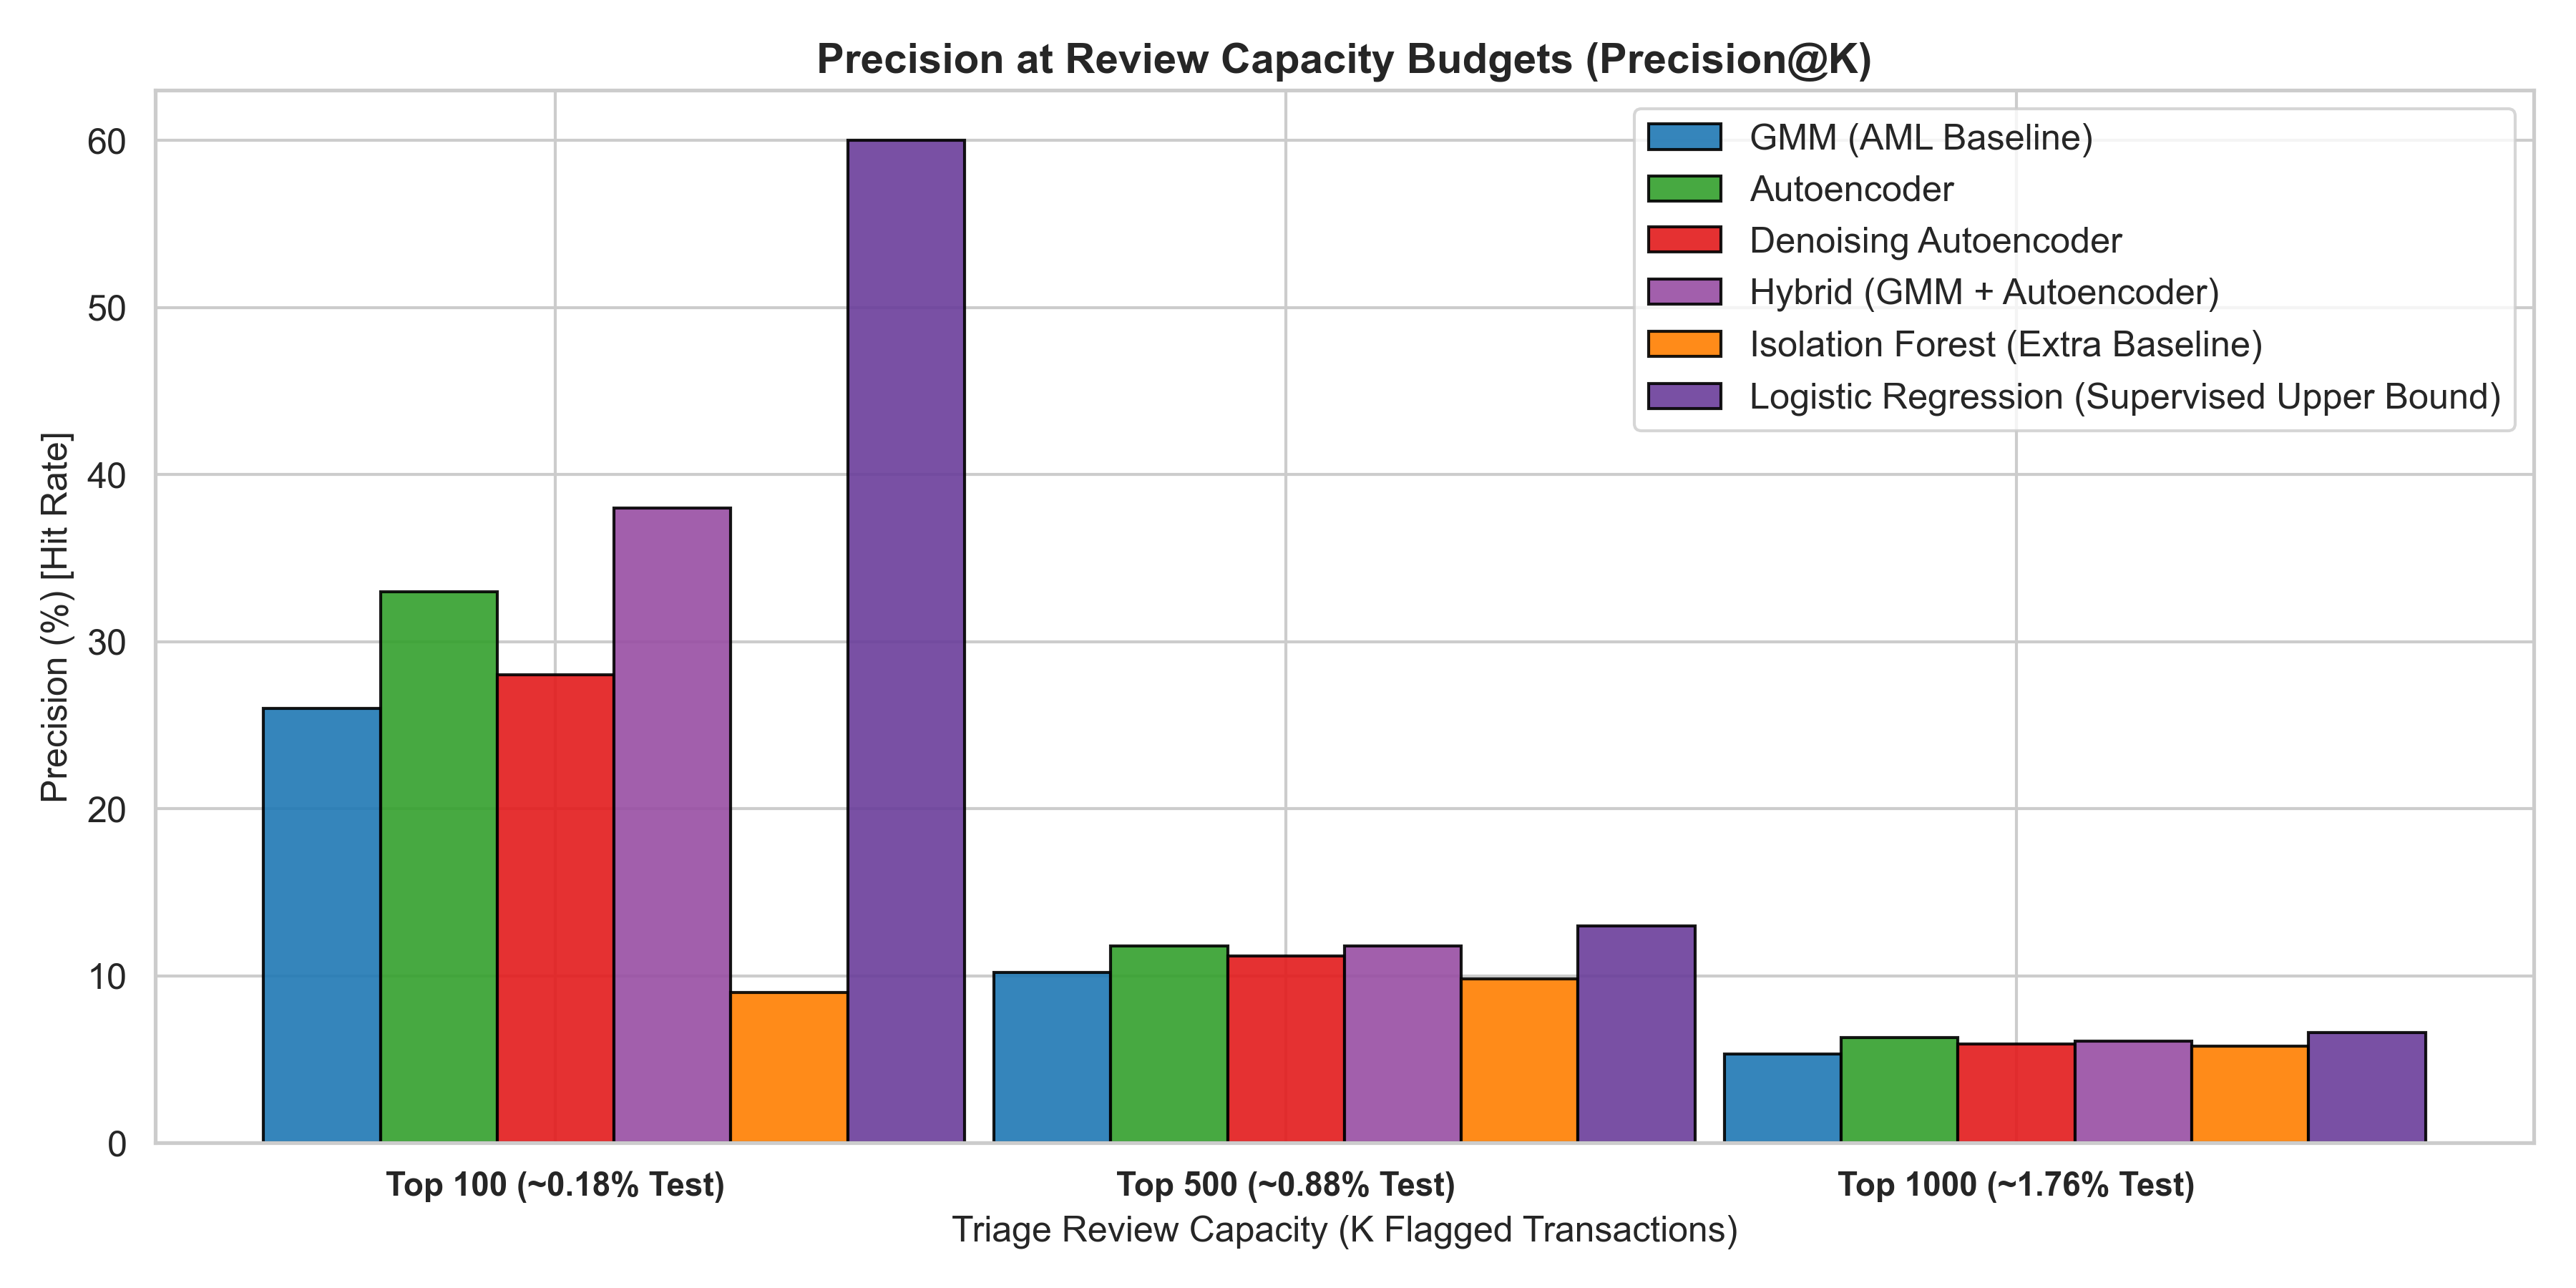

In [14]:
# Visual 8: Precision at Review Capacity (Precision@K)
display(Image(filename=os.path.join(repo_root, "results/precision_at_k_comparison.png")))


## 7. Operational Threshold Analysis (Validation -> Test)

In production triage, thresholds cannot be tuned on the test set. Here, decision thresholds are selected **strictly on the Validation partition** (e.g. Target FPR = 0.5% and Maximum F1) and applied **unchanged to the Test partition**.

We quantify the operational trade-off: **How many legitimate customers are flagged per fraud caught?**
$$\text{Review Burden} = \frac{\text{False Positives}}{\text{True Positives}}$$


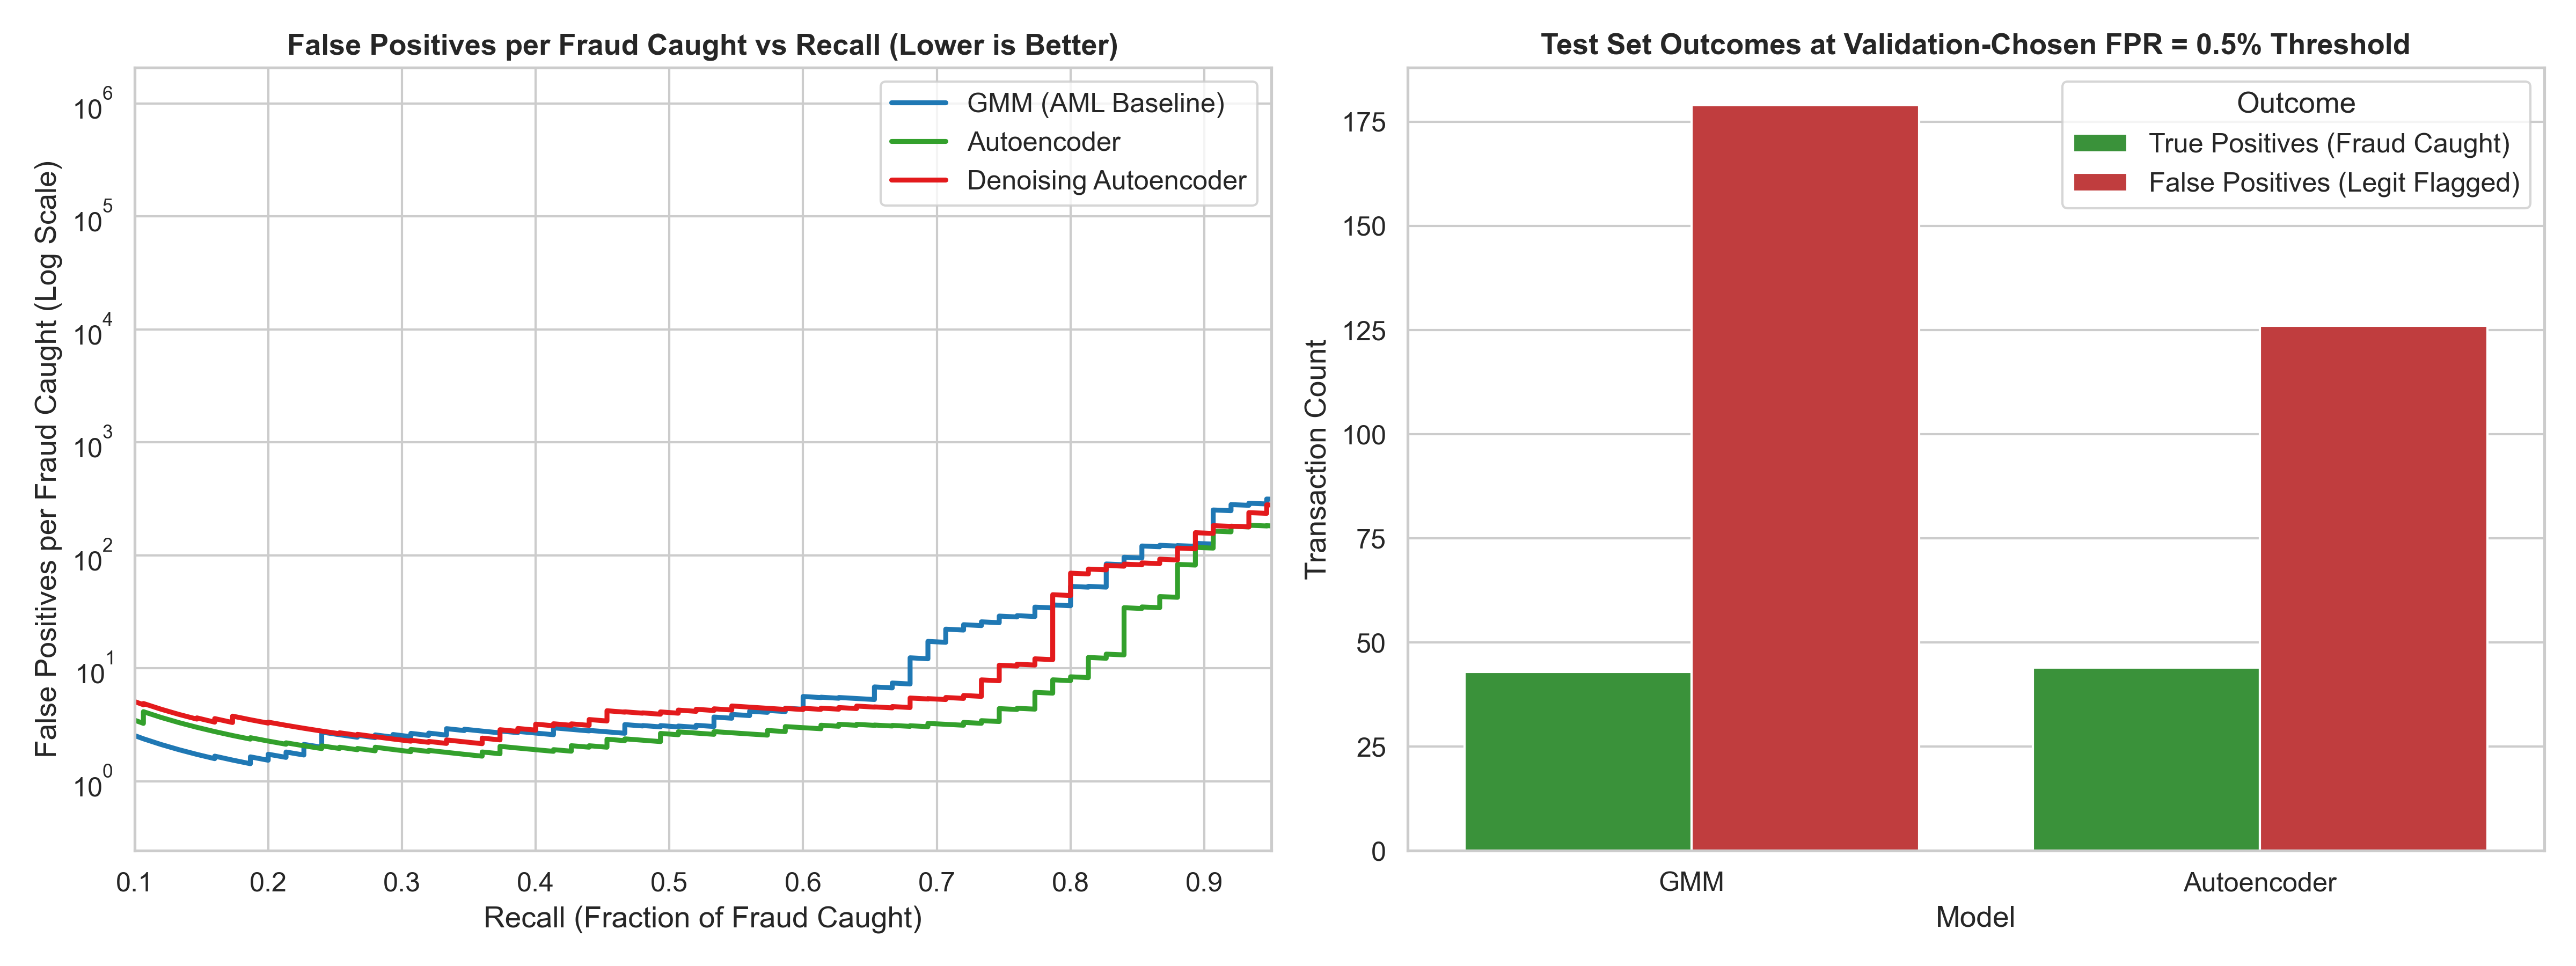

Model,Val Threshold (0.5% FPR),Test TP (Frauds Caught),Test FP (Legit Flagged),Test Recall,Test Precision,Legit Flagged per Fraud
GMM (AML Baseline),71.14,43 / 75,179,57.3%,19.4%,4.2 : 1
Autoencoder,5.0429,44 / 75,126,58.7%,25.9%,2.9 : 1


In [15]:
# Visual 9: Threshold Trade-off & Operational Test Outcomes
display(Image(filename=os.path.join(repo_root, "results/threshold_tradeoff.png")))

with open(os.path.join(repo_root, "results/metrics.json")) as f:
    full_metrics = json.load(f)

gmm_eval = full_metrics["GMM (AML Baseline)"]["val_derived_thresholds"]["fpr_0.5pct"]["test_eval"]
ae_eval = full_metrics["Autoencoder"]["val_derived_thresholds"]["fpr_0.5pct"]["test_eval"]

thresh_summary = pd.DataFrame([
    {
        "Model": "GMM (AML Baseline)",
        "Val Threshold (0.5% FPR)": f"{gmm_eval['threshold']:.2f}",
        "Test TP (Frauds Caught)": f"{gmm_eval['tp']} / 75",
        "Test FP (Legit Flagged)": f"{gmm_eval['fp']:,}",
        "Test Recall": f"{gmm_eval['recall']*100:.1f}%",
        "Test Precision": f"{gmm_eval['precision']*100:.1f}%",
        "Legit Flagged per Fraud": f"{gmm_eval['fp_per_fraud_caught']:.1f} : 1"
    },
    {
        "Model": "Autoencoder",
        "Val Threshold (0.5% FPR)": f"{ae_eval['threshold']:.4f}",
        "Test TP (Frauds Caught)": f"{ae_eval['tp']} / 75",
        "Test FP (Legit Flagged)": f"{ae_eval['fp']:,}",
        "Test Recall": f"{ae_eval['recall']*100:.1f}%",
        "Test Precision": f"{ae_eval['precision']*100:.1f}%",
        "Legit Flagged per Fraud": f"{ae_eval['fp_per_fraud_caught']:.1f} : 1"
    }
])
display(thresh_summary)


## 8. Error Analysis: Top False Positives & Missed Frauds

We dissect the failure modes of both models by isolating:
1. **Top False Positives:** Legitimate transactions that generated the highest anomaly scores.
2. **Missed Frauds (False Negatives):** True fraudulent transactions that received the lowest anomaly scores.
We analyze transaction amounts and the most informative PCA components ($V_{14}, V_{12}, V_{17}$).


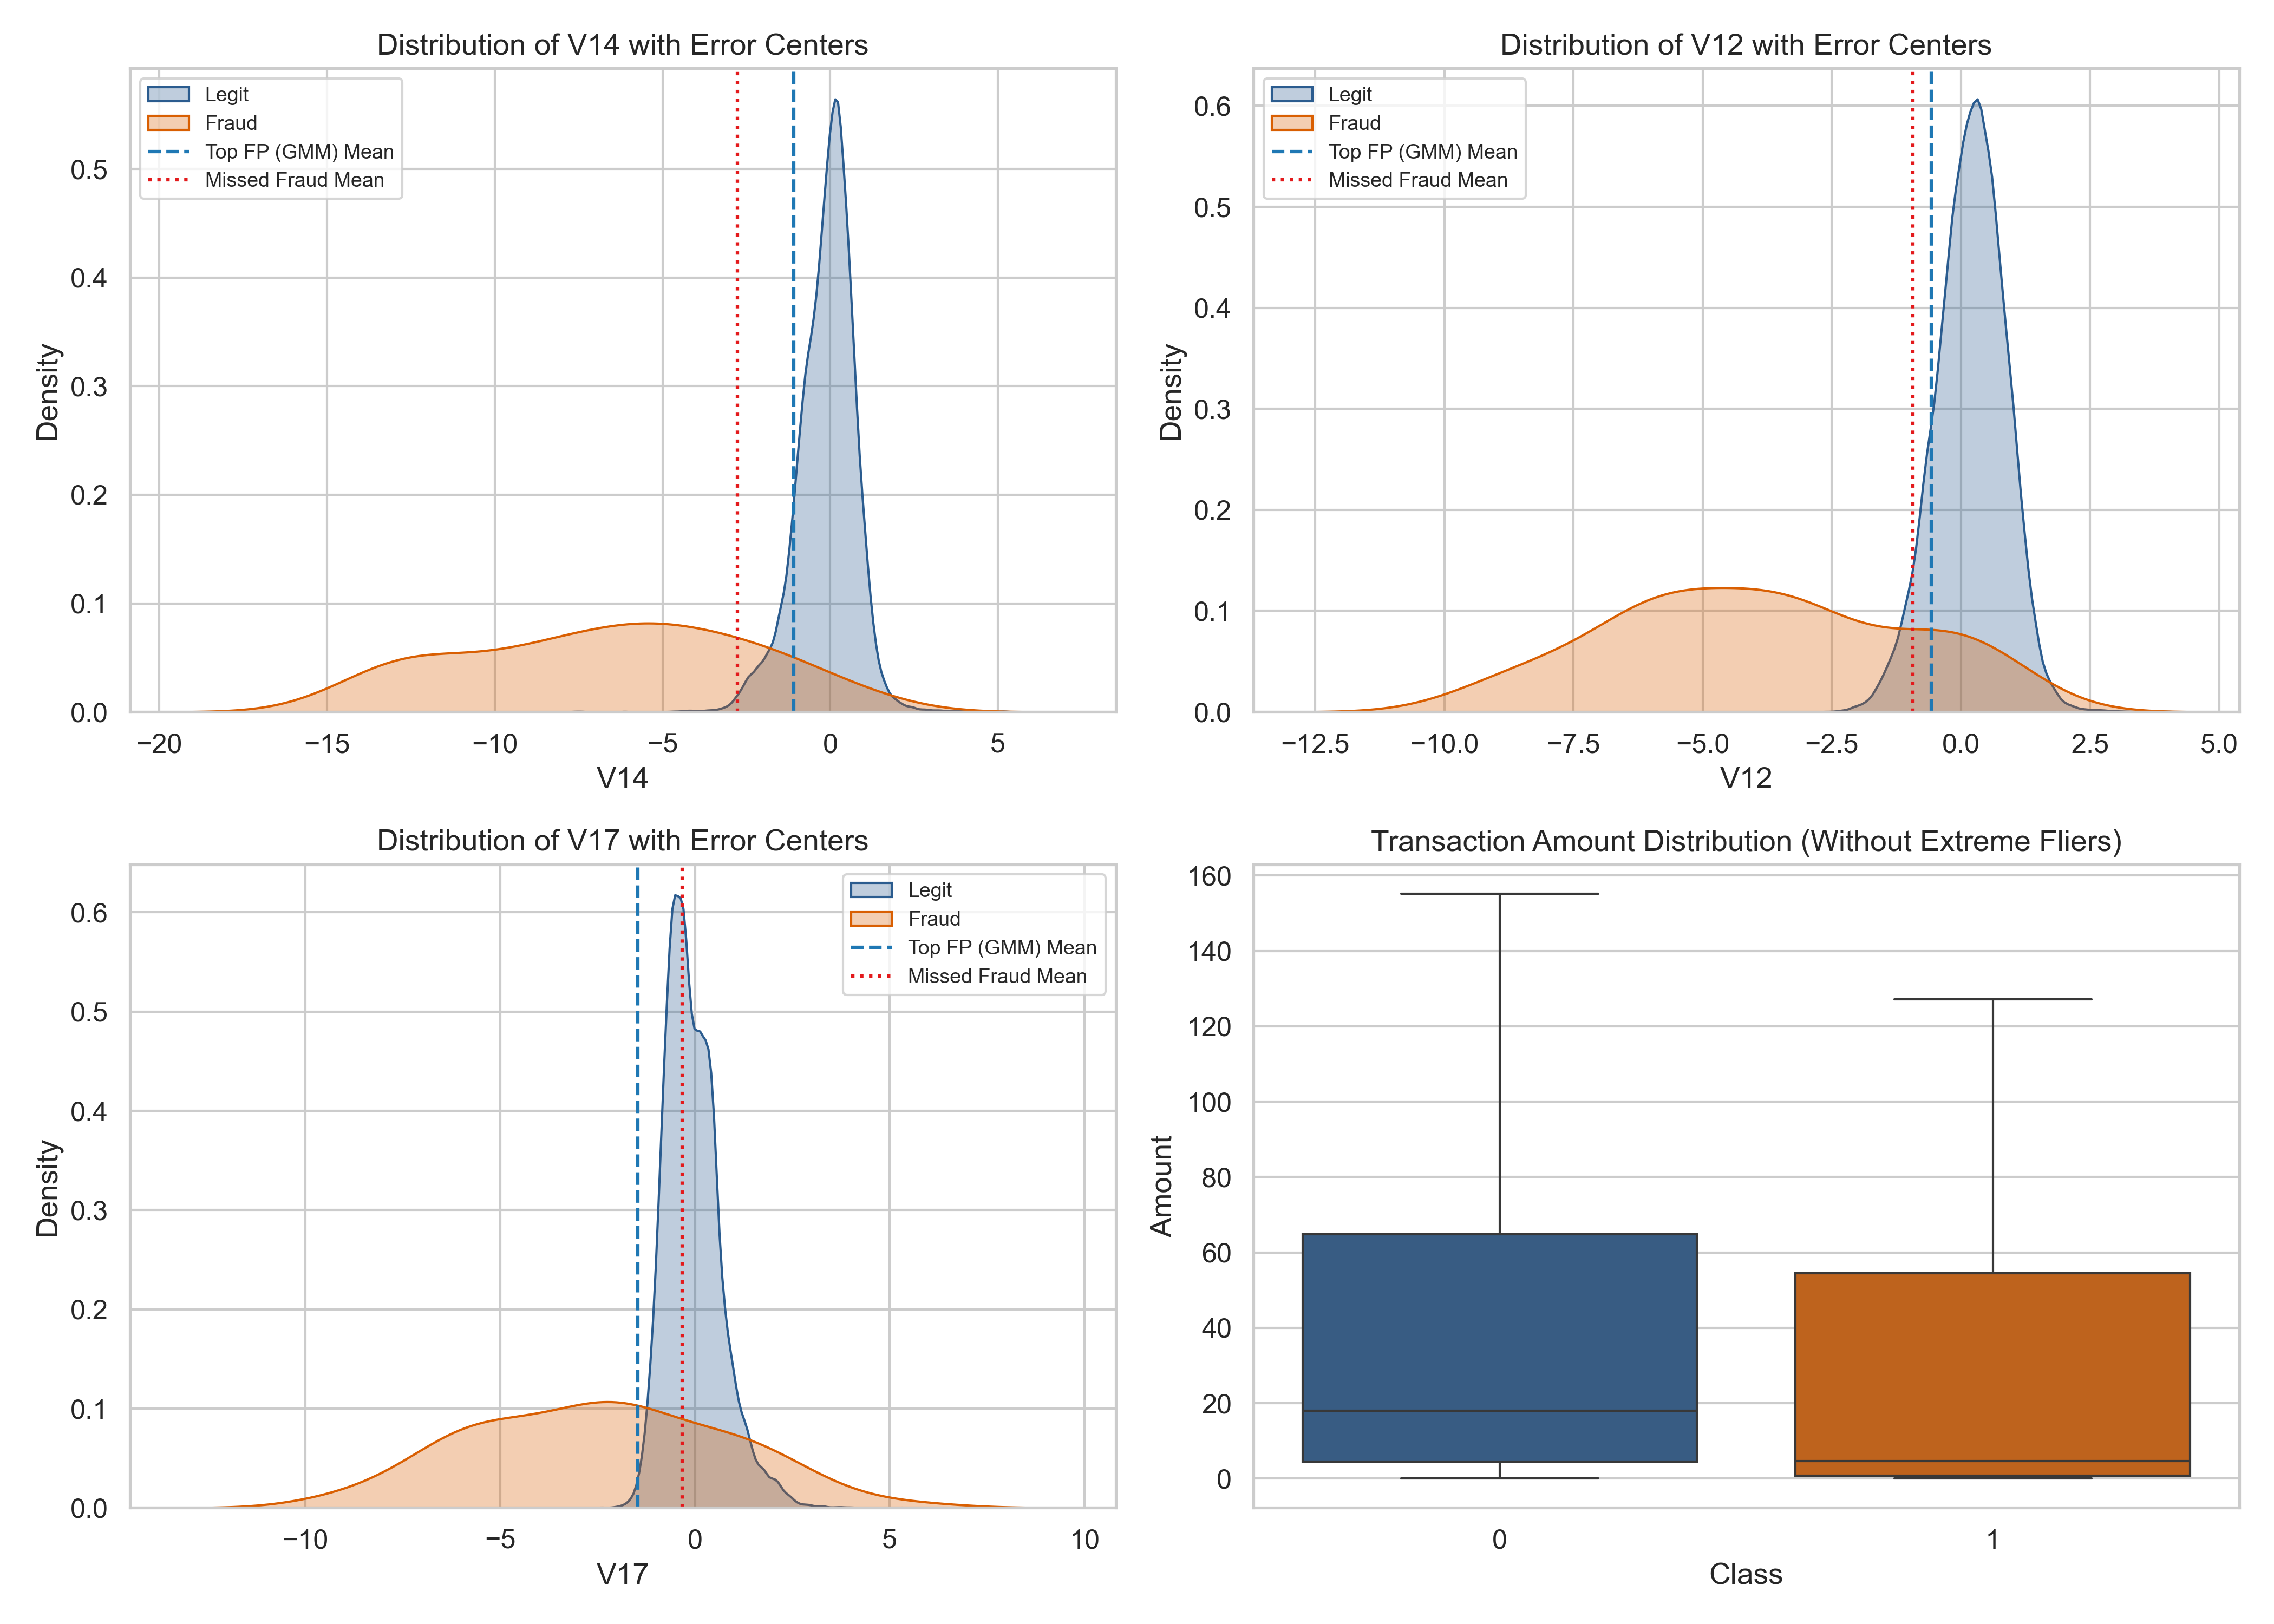

In [16]:
# Visual 10: Error Analysis Feature Distributions
display(Image(filename=os.path.join(repo_root, "results/error_analysis.png")))


## 9. Insights, Discussion, Limitations & Conclusion

### Comparative Insights (GMM vs Autoencoder):
1. **Manifold Geometry vs Gaussian Density:** The Autoencoder consistently outperforms GMM across strict operational False Positive Rate budgets. At a 0.5% FPR budget, the Autoencoder captures **77.33% of frauds** compared to **65.33%** for GMM, and achieves superior top-queue precision (Precision@100 = 33.00% vs 26.00%).
2. **Why Autoencoder Wins in Low-FPR Regimes:** Financial transaction behavior exhibits non-convex, non-linear manifolds. GMM relies on convex ellipsoidal Gaussian components, which in 29 dimensions struggle with the curse of dimensionality and penalize legitimate high-variance outliers (e.g., legitimate high-dollar purchases). The Autoencoder's non-linear bottleneck compresses the true latent manifold more compactly.
3. **Where GMM Retains Utility:** GMM outputs an exact probability density and mathematically rigorous log-likelihoods, allowing probabilistic calibration and explicit covariance inspection.
4. **The Cost of Unsupervised Learning:** While both unsupervised models attain ~0.22 PR-AUC (over 166x above the 0.132% base rate), the supervised upper bound achieves 0.7473 PR-AUC. This illustrates that while anomaly triage effectively flags novel outliers without labels, supervised models directly optimize the discriminant boundary separating fraud from legitimate behavior.
5. **Limitations:** The dataset is restricted to 48 hours and PCA-anonymized features, preventing the integration of multi-week velocity metrics, behavioral graph embeddings, and device telemetry. In production, anomaly triage scores should serve as dynamic risk signals within a tiered orchestration pipeline rather than standalone binary decision makers.
